In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction/E Commerce Dataset.xlsx
/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction/E Commerce Dataset.xlsx
/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset dimensions:", df.shape)

Number of rows: 7043
Number of columns: 21
Dataset dimensions: (7043, 21)


In [7]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [11]:
# Convert TotalCharges into numerical format
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check missing values
print(df.isnull().sum()[df.isnull().sum() > 0])

TotalCharges    11
dtype: int64


In [12]:
# Remove customerID
df = df.drop(columns=['customerID'])

print("Updated dataset shape:", df.shape)

Updated dataset shape: (7043, 20)


In [13]:
# Input features
X = df.drop(columns=['Churn'])

# Target variable
y = df['Churn']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [14]:
y = y.map({
    'No': 0,
    'Yes': 1
})

print(y.value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 19)
Testing features: (1409, 19)
Training target: (5634,)
Testing target: (1409,)


In [16]:
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [18]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5634, 45)
Processed testing shape: (1409, 45)


In [19]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel='linear',
    C=1.0,
    random_state=42
)

In [20]:
svm_model.fit(X_train_processed, y_train)

SVC(kernel='linear', random_state=42)

In [21]:
y_pred = svm_model.predict(X_test_processed)

print(y_pred[:10])

[0 1 0 0 0 1 1 0 0 0]


In [22]:
print(svm_model.support_vectors_.shape)
print("Number of support vectors:", len(svm_model.support_))

(2570, 45)
Number of support vectors: 2570


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7877927608232789
Precision: 0.6175548589341693
Recall: 0.5267379679144385
F1 Score: 0.5685425685425686

Confusion Matrix:
[[913 122]
 [177 197]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.62      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [24]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_scores = svm_model.decision_function(X_test_processed)

print("ROC-AUC:", roc_auc_score(y_test, y_scores))
print("PR-AUC:", average_precision_score(y_test, y_scores))

ROC-AUC: 0.825262858766695
PR-AUC: 0.6188135121869615


In [25]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('svm', SVC(kernel='linear', random_state=42))
])

In [26]:
param_grid = {
    'svm__C': [0.01, 0.1, 1, 10, 100]
}

In [27]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [28]:
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [29]:
import time

start_time = time.time()

grid_search.fit(X_train, y_train)

end_time = time.time()

print("Optimization completed!")

print("Best Parameters:", grid_search.best_params_)

print("Best Cross-Validation PR-AUC:", grid_search.best_score_)

print("Optimization Time:", round(end_time - start_time, 2), "seconds")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Optimization completed!
Best Parameters: {'svm__C': 0.01}
Best Cross-Validation PR-AUC: 0.652629541088717
Optimization Time: 42.88 seconds


In [30]:
import pandas as pd

results = pd.DataFrame(grid_search.cv_results_)

svm_results = results[[
    'param_svm__C',
    'mean_test_score',
    'std_test_score',
    'mean_fit_time'
]]

svm_results = svm_results.sort_values(
    by='mean_test_score',
    ascending=False
)

print(svm_results)

   param_svm__C  mean_test_score  std_test_score  mean_fit_time
0          0.01         0.652630        0.015772       1.004607
1          0.10         0.651558        0.016223       1.109273
3         10.00         0.650851        0.016281       3.940719
4        100.00         0.650466        0.016196      18.063924
2          1.00         0.650430        0.016230       1.548108


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Retrieve the best model
best_svm = grid_search.best_estimator_

# Make predictions
y_pred_optimized = best_svm.predict(X_test)

# Obtain decision scores
y_scores_optimized = best_svm.decision_function(X_test)

# Evaluate performance
print("OPTIMIZED SVM RESULTS")

print("Accuracy:", accuracy_score(y_test, y_pred_optimized))
print("Precision:", precision_score(y_test, y_pred_optimized))
print("Recall:", recall_score(y_test, y_pred_optimized))
print("F1 Score:", f1_score(y_test, y_pred_optimized))

print("ROC-AUC:", roc_auc_score(y_test, y_scores_optimized))
print("PR-AUC:", average_precision_score(y_test, y_scores_optimized))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_optimized))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_optimized))

OPTIMIZED SVM RESULTS
Accuracy: 0.7934705464868701
Precision: 0.6309148264984227
Recall: 0.5347593582887701
F1 Score: 0.5788712011577424
ROC-AUC: 0.8308739569609134
PR-AUC: 0.6246718940807622

Confusion Matrix:
[[918 117]
 [174 200]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.63      0.53      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



In [32]:
import time, warnings
import numpy as np
import pandas as pd
import optuna
from joblib import Memory
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold,
    cross_val_score, train_test_split
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---------------- CONFIG ----------------
SEARCH_N = 6000      # rows used during the search (lower = faster)
N_ITER   = 30        # random-search iterations / Optuna trials
N_SPLITS = 5
SEED     = 42
# ----------------------------------------

# Stratified subsample for the search phase only
if len(X_train) > SEARCH_N:
    X_search, _, y_search, _ = train_test_split(
        X_train, y_train, train_size=SEARCH_N,
        stratify=y_train, random_state=SEED
    )
else:
    X_search, y_search = X_train, y_train

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# Cache fitted preprocessing so it isn't recomputed for every candidate
memory = Memory("./svm_cache", verbose=0)

svm_pipeline = Pipeline(
    [('preprocessor', preprocessor),
     ('svm', SVC(cache_size=1000, random_state=SEED))],
    memory=memory
)

# ================= 1. GRID SEARCH =================
svm_grid = [
    {'svm__kernel': ['linear'],
     'svm__C': [0.01, 0.1, 1, 10],
     'svm__class_weight': [None, 'balanced']},
    {'svm__kernel': ['rbf'],
     'svm__C': [0.1, 1, 10],
     'svm__gamma': ['scale', 'auto'],
     'svm__class_weight': [None, 'balanced']},
    {'svm__kernel': ['poly'],
     'svm__C': [0.1, 1, 10],
     'svm__gamma': ['scale'],
     'svm__degree': [2, 3],
     'svm__class_weight': [None, 'balanced']},
]

grid_svm = GridSearchCV(
    svm_pipeline, svm_grid,
    scoring='average_precision', cv=cv,
    n_jobs=-1, refit=False, return_train_score=False, verbose=0
)
start = time.time()
grid_svm.fit(X_search, y_search)
grid_time = time.time() - start
grid_fits = len(grid_svm.cv_results_['params']) * N_SPLITS

print("GRID SEARCH RESULTS")
print("Best Parameters:", grid_svm.best_params_)
print("Best CV PR-AUC:", round(grid_svm.best_score_, 4))
print("Execution Time:", round(grid_time, 2), "seconds\n")

# ================= 2. RANDOMIZED SEARCH =================
svm_random_space = [
    {'svm__kernel': ['linear'],
     'svm__C': loguniform(0.01, 10),
     'svm__class_weight': [None, 'balanced']},
    {'svm__kernel': ['rbf'],
     'svm__C': loguniform(0.01, 100),
     'svm__gamma': ['scale', 'auto'],
     'svm__class_weight': [None, 'balanced']},
    {'svm__kernel': ['poly'],
     'svm__C': loguniform(0.01, 10),
     'svm__gamma': ['scale'],
     'svm__degree': [2, 3],
     'svm__class_weight': [None, 'balanced']},
]

random_svm = RandomizedSearchCV(
    svm_pipeline, svm_random_space, n_iter=N_ITER,
    scoring='average_precision', cv=cv,
    n_jobs=-1, random_state=SEED,
    refit=False, return_train_score=False, verbose=0
)
start = time.time()
random_svm.fit(X_search, y_search)
random_time = time.time() - start
random_fits = N_ITER * N_SPLITS

print("RANDOMIZED SEARCH RESULTS")
print("Best Parameters:", random_svm.best_params_)
print("Best CV PR-AUC:", round(random_svm.best_score_, 4))
print("Execution Time:", round(random_time, 2), "seconds\n")

# ================= 3. OPTUNA (TPE) =================
def svm_objective(trial):
    kernel = trial.suggest_categorical('kernel', ['linear', 'rbf', 'poly'])
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced'])

    params = {'kernel': kernel, 'class_weight': class_weight}
    if kernel == 'linear':
        params['C'] = trial.suggest_float('C', 0.01, 10, log=True)
    elif kernel == 'rbf':
        params['C'] = trial.suggest_float('C', 0.01, 100, log=True)
        params['gamma'] = trial.suggest_categorical('gamma', ['scale', 'auto'])
    else:
        params['C'] = trial.suggest_float('C', 0.01, 10, log=True)
        params['gamma'] = 'scale'
        params['degree'] = trial.suggest_int('degree', 2, 3)

    model = Pipeline(
        [('preprocessor', preprocessor),
         ('svm', SVC(cache_size=1000, random_state=SEED, **params))],
        memory=memory
    )
    return cross_val_score(
        model, X_search, y_search,
        scoring='average_precision', cv=cv, n_jobs=N_SPLITS   # parallel folds
    ).mean()

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
start = time.time()
study.optimize(svm_objective, n_trials=N_ITER)
optuna_time = time.time() - start
optuna_fits = len(study.trials) * N_SPLITS

print("OPTUNA RESULTS")
print("Best Parameters:", study.best_params)
print("Best CV PR-AUC:", round(study.best_value, 4))
print("Execution Time:", round(optuna_time, 2), "seconds\n")

# ================= SEARCH COMPARISON =================
optimization_comparison = pd.DataFrame([
    {'Method': 'GridSearchCV', 'Best CV PR-AUC': grid_svm.best_score_,
     'Execution Time': grid_time, 'Number of Fits': grid_fits},
    {'Method': 'RandomizedSearchCV', 'Best CV PR-AUC': random_svm.best_score_,
     'Execution Time': random_time, 'Number of Fits': random_fits},
    {'Method': 'Optuna TPE', 'Best CV PR-AUC': study.best_value,
     'Execution Time': optuna_time, 'Number of Fits': optuna_fits},
]).sort_values('Best CV PR-AUC', ascending=False)
print(optimization_comparison.to_string(index=False))

# ================= FINAL MODELS (refit on FULL training data) =================
def build_final(params):
    # params must be prefixed with 'svm__'
    model = clone(svm_pipeline)
    model.set_params(**params)
    return model.fit(X_train, y_train)

optuna_params = {f"svm__{k}": v for k, v in study.best_params.items()}
if optuna_params.get('svm__kernel') == 'poly':
    optuna_params['svm__gamma'] = 'scale'

best_grid_svm   = build_final(grid_svm.best_params_)
best_random_svm = build_final(random_svm.best_params_)
best_optuna_svm = build_final(optuna_params)

def evaluate_svm(name, model):
    y_pred = model.predict(X_test)
    y_scores = model.decision_function(X_test)
    return {
        'Optimization': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_scores),
        'PR-AUC': average_precision_score(y_test, y_scores),
    }

svm_test_comparison = pd.DataFrame([
    evaluate_svm('GridSearchCV', best_grid_svm),
    evaluate_svm('RandomizedSearchCV', best_random_svm),
    evaluate_svm('Optuna TPE', best_optuna_svm),
])
print("\nTEST SET COMPARISON")
print(svm_test_comparison.round(4).to_string(index=False))

GRID SEARCH RESULTS
Best Parameters: {'svm__C': 0.01, 'svm__class_weight': 'balanced', 'svm__kernel': 'linear'}
Best CV PR-AUC: 0.6581
Execution Time: 88.19 seconds

RANDOMIZED SEARCH RESULTS
Best Parameters: {'svm__C': np.float64(0.07068974950624607), 'svm__class_weight': 'balanced', 'svm__gamma': 'auto', 'svm__kernel': 'rbf'}
Best CV PR-AUC: 0.656
Execution Time: 74.38 seconds

OPTUNA RESULTS
Best Parameters: {'kernel': 'linear', 'class_weight': 'balanced', 'C': 0.02117260546317316}
Best CV PR-AUC: 0.6591
Execution Time: 73.39 seconds

            Method  Best CV PR-AUC  Execution Time  Number of Fits
        Optuna TPE        0.659074       73.391537             150
      GridSearchCV        0.658121       88.194498             160
RandomizedSearchCV        0.655963       74.382033             150

TEST SET COMPARISON
      Optimization  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
      GridSearchCV    0.7055     0.4685  0.8155    0.5951   0.8345  0.6312
RandomizedSearchC

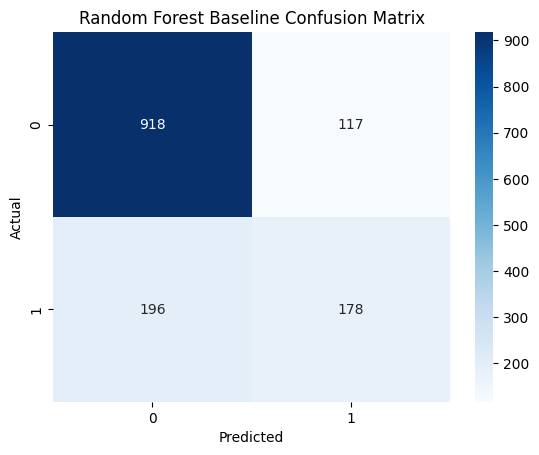

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from scipy.stats import randint

import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)
rf_baseline = Pipeline([
    ('preprocessor', preprocessor),

    ('rf', RandomForestClassifier(
        random_state=SEED,
        n_jobs=-1
    ))
])
start_time = time.time()

rf_baseline.fit(X_train, y_train)

baseline_time = time.time() - start_time

# Predictions
y_pred_rf = rf_baseline.predict(X_test)

# Probability of churn
y_prob_rf = rf_baseline.predict_proba(X_test)[:, 1]

# Evaluation
rf_baseline_results = {
    'Model': 'Baseline RF',
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1 Score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf),
    'PR-AUC': average_precision_score(y_test, y_prob_rf),
    'Training Time': baseline_time
}

pd.DataFrame([rf_baseline_results])

start_time = time.time()

rf_baseline.fit(X_train, y_train)

baseline_time = time.time() - start_time

# Predictions
y_pred_rf = rf_baseline.predict(X_test)

# Probability of churn
y_prob_rf = rf_baseline.predict_proba(X_test)[:, 1]

# Evaluation
rf_baseline_results = {
    'Model': 'Baseline RF',
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1 Score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf),
    'PR-AUC': average_precision_score(y_test, y_prob_rf),
    'Training Time': baseline_time
}

pd.DataFrame([rf_baseline_results])
cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Baseline Confusion Matrix')
plt.show()

GRID SEARCH RESULTS
Best Parameters: {'rf__bootstrap': True, 'rf__class_weight': None, 'rf__criterion': 'gini', 'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__max_samples': 0.6, 'rf__min_samples_leaf': 3, 'rf__n_estimators': 300}
Best CV PR-AUC: 0.6572
Execution Time: 667.08 seconds

RANDOMIZED SEARCH RESULTS
Best Parameters: {'rf__bootstrap': True, 'rf__class_weight': None, 'rf__criterion': 'log_loss', 'rf__max_depth': 10, 'rf__max_features': 0.7, 'rf__max_samples': np.float64(0.5687604720729966), 'rf__min_samples_leaf': 4, 'rf__min_samples_split': 10, 'rf__n_estimators': 583}
Best CV PR-AUC: 0.6646
Execution Time: 361.81 seconds

OPTUNA RESULTS
Best Parameters: {'bootstrap': True, 'criterion': 'entropy', 'n_estimators': 216, 'max_depth': 10, 'min_samples_split': 8, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_samples': 0.7590766049860157, 'class_weight': 'balanced_subsample'}
Best CV PR-AUC: 0.6647
Execution Time: 243.66 seconds



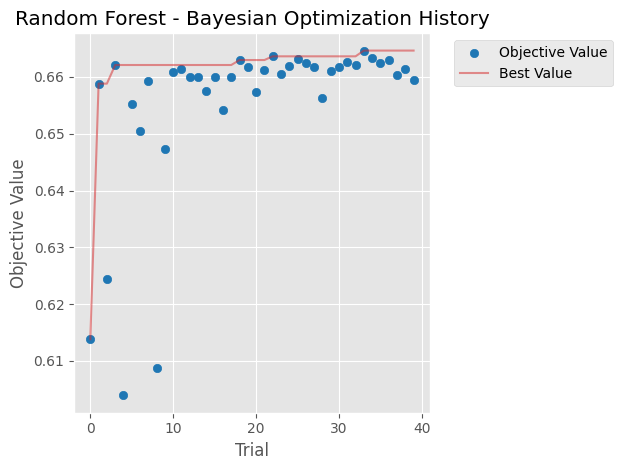


SEARCH COMPARISON
            Method  Best CV PR-AUC  Execution Time  Number of Fits
        Optuna TPE          0.6647        243.6588             200
RandomizedSearchCV          0.6646        361.8136             200
      GridSearchCV          0.6572        667.0817             480


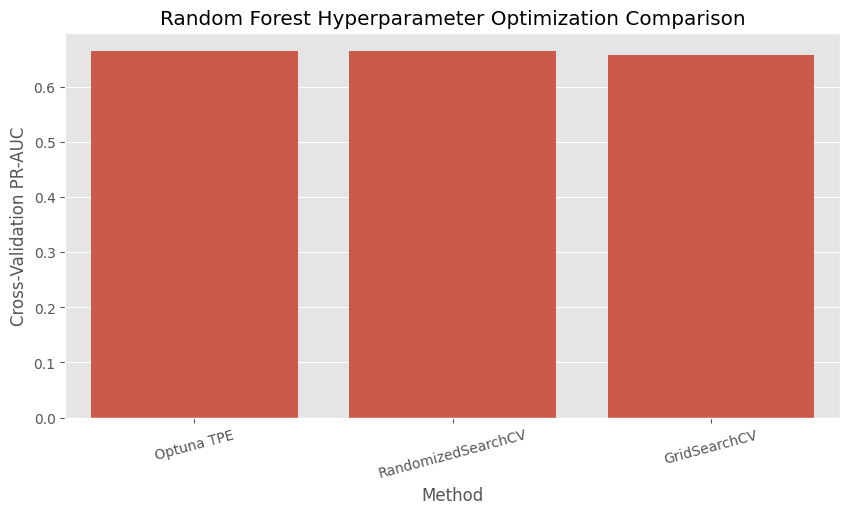

Best RF Optimization Method: Optuna TPE

BEST HYPERPARAMETERS PER METHOD
                  GridSearchCV RandomizedSearchCV          Optuna TPE
bootstrap                 True               True                True
class_weight                 -                  -  balanced_subsample
criterion                 gini           log_loss             entropy
max_depth                    -                 10                  10
max_features              sqrt                0.7                 0.5
max_samples                0.6            0.56876            0.759077
min_samples_leaf             3                  4                   4
min_samples_split            -                 10                   8
n_estimators               300                583                 216

TOP 5 GRID CONFIGURATIONS
                                                                                                                                                                                                        

In [34]:
import time, warnings
import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Memory
from scipy.stats import randint, uniform
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold,
    cross_val_score, train_test_split
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---------------- CONFIG ----------------
SEARCH_N = 8000      # rows used during the search (lower = faster)
N_ITER   = 40        # random-search iterations / Optuna trials
N_SPLITS = 5
SEED     = 42
# ----------------------------------------

# Stratified subsample for the search phase only
if len(X_train) > SEARCH_N:
    X_search, _, y_search, _ = train_test_split(
        X_train, y_train, train_size=SEARCH_N,
        stratify=y_train, random_state=SEED
    )
else:
    X_search, y_search = X_train, y_train

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# Cache fitted preprocessing so it isn't recomputed for every candidate
rf_memory = Memory("./rf_cache", verbose=0)

# n_jobs=1 inside the RF: parallelism is handled by the CV folds instead
rf_pipeline = Pipeline(
    [('preprocessor', preprocessor),
     ('rf', RandomForestClassifier(random_state=SEED, n_jobs=1))],
    memory=rf_memory
)

# ================= 1. GRID SEARCH =================
# Two branches (like the SVM kernels): bootstrap=True and bootstrap=False
rf_param_grid = [
    {'rf__bootstrap': [True],
     'rf__max_samples': [0.6, None],
     'rf__criterion': ['gini', 'entropy'],
     'rf__n_estimators': [300],
     'rf__max_depth': [None, 15],
     'rf__min_samples_leaf': [1, 3],
     'rf__max_features': ['sqrt', 0.7],
     'rf__class_weight': [None, 'balanced_subsample']},      # 64 candidates
    {'rf__bootstrap': [False],
     'rf__criterion': ['gini', 'entropy'],
     'rf__n_estimators': [300],
     'rf__max_depth': [None, 15],
     'rf__min_samples_leaf': [1, 3],
     'rf__max_features': ['sqrt', 0.7],
     'rf__class_weight': [None, 'balanced']},                # 32 candidates
]

rf_grid = GridSearchCV(
    rf_pipeline, rf_param_grid,
    scoring='average_precision', cv=cv,
    n_jobs=-1, refit=False, return_train_score=False, verbose=0
)
start = time.time()
rf_grid.fit(X_search, y_search)
rf_grid_time = time.time() - start
rf_grid_fits = len(rf_grid.cv_results_['params']) * N_SPLITS

print("GRID SEARCH RESULTS")
print("Best Parameters:", rf_grid.best_params_)
print("Best CV PR-AUC:", round(rf_grid.best_score_, 4))
print("Execution Time:", round(rf_grid_time, 2), "seconds\n")

# ================= 2. RANDOMIZED SEARCH =================
rf_random_space = [
    {'rf__bootstrap': [True],
     'rf__max_samples': uniform(0.5, 0.5),                    # 0.5 - 1.0
     'rf__criterion': ['gini', 'entropy', 'log_loss'],
     'rf__n_estimators': randint(150, 601),
     'rf__max_depth': [None, 10, 15, 20, 30, 40],
     'rf__min_samples_split': randint(2, 11),
     'rf__min_samples_leaf': randint(1, 6),
     'rf__max_features': ['sqrt', 'log2', 0.5, 0.7],
     'rf__class_weight': [None, 'balanced', 'balanced_subsample']},
    {'rf__bootstrap': [False],
     'rf__criterion': ['gini', 'entropy', 'log_loss'],
     'rf__n_estimators': randint(150, 601),
     'rf__max_depth': [None, 10, 15, 20, 30, 40],
     'rf__min_samples_split': randint(2, 11),
     'rf__min_samples_leaf': randint(1, 6),
     'rf__max_features': ['sqrt', 'log2', 0.5, 0.7],
     'rf__class_weight': [None, 'balanced']},
]

rf_random = RandomizedSearchCV(
    rf_pipeline, rf_random_space, n_iter=N_ITER,
    scoring='average_precision', cv=cv,
    n_jobs=-1, random_state=SEED,
    refit=False, return_train_score=False, verbose=0
)
start = time.time()
rf_random.fit(X_search, y_search)
rf_random_time = time.time() - start
rf_random_fits = N_ITER * N_SPLITS

print("RANDOMIZED SEARCH RESULTS")
print("Best Parameters:", rf_random.best_params_)
print("Best CV PR-AUC:", round(rf_random.best_score_, 4))
print("Execution Time:", round(rf_random_time, 2), "seconds\n")

# ================= 3. OPTUNA (TPE) =================
def rf_objective(trial):
    bootstrap = trial.suggest_categorical('bootstrap', [True, False])

    params = {
        'bootstrap':         bootstrap,
        'criterion':         trial.suggest_categorical('criterion', ['gini', 'entropy', 'log_loss']),
        'n_estimators':      trial.suggest_int('n_estimators', 150, 600),
        'max_depth':         trial.suggest_categorical('max_depth', [None, 10, 15, 20, 30, 40]),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 1, 5),
        'max_features':      trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5, 0.7]),
    }
    if bootstrap:
        params['max_samples'] = trial.suggest_float('max_samples', 0.5, 1.0)
        params['class_weight'] = trial.suggest_categorical(
            'class_weight_bs', [None, 'balanced', 'balanced_subsample'])
    else:
        params['class_weight'] = trial.suggest_categorical(
            'class_weight_nobs', [None, 'balanced'])

    # Store the exact RF params so the final model is built without any renaming
    trial.set_user_attr('model_params', params)

    model = Pipeline(
        [('preprocessor', preprocessor),
         ('rf', RandomForestClassifier(random_state=SEED, n_jobs=1, **params))],
        memory=rf_memory
    )
    return cross_val_score(
        model, X_search, y_search,
        scoring='average_precision', cv=cv, n_jobs=N_SPLITS   # parallel folds
    ).mean()

study_rf = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
start = time.time()
study_rf.optimize(rf_objective, n_trials=N_ITER)
rf_optuna_time = time.time() - start
rf_optuna_fits = len(study_rf.trials) * N_SPLITS
optuna_best_model_params = study_rf.best_trial.user_attrs['model_params']

print("OPTUNA RESULTS")
print("Best Parameters:", optuna_best_model_params)
print("Best CV PR-AUC:", round(study_rf.best_value, 4))
print("Execution Time:", round(rf_optuna_time, 2), "seconds\n")

# Optimization history plot
optuna.visualization.matplotlib.plot_optimization_history(study_rf)
plt.title("Random Forest - Bayesian Optimization History")
plt.show()

# ================= SEARCH COMPARISON =================
rf_optimization_results = pd.DataFrame([
    {'Method': 'GridSearchCV',       'Best CV PR-AUC': rf_grid.best_score_,
     'Execution Time': rf_grid_time,   'Number of Fits': rf_grid_fits},
    {'Method': 'RandomizedSearchCV', 'Best CV PR-AUC': rf_random.best_score_,
     'Execution Time': rf_random_time, 'Number of Fits': rf_random_fits},
    {'Method': 'Optuna TPE',         'Best CV PR-AUC': study_rf.best_value,
     'Execution Time': rf_optuna_time, 'Number of Fits': rf_optuna_fits},
]).sort_values('Best CV PR-AUC', ascending=False).reset_index(drop=True)

print("\nSEARCH COMPARISON")
print(rf_optimization_results.round(4).to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=rf_optimization_results, x='Method', y='Best CV PR-AUC')
plt.title('Random Forest Hyperparameter Optimization Comparison')
plt.ylabel('Cross-Validation PR-AUC')
plt.xticks(rotation=15)
plt.show()

best_rf_method = rf_optimization_results.iloc[0]['Method']
print("Best RF Optimization Method:", best_rf_method)

# ================= BEST PARAMETERS SUMMARY =================
strip = lambda d: {k.replace('rf__', ''): v for k, v in d.items()}
best_params_table = pd.DataFrame({
    'GridSearchCV':       pd.Series(strip(rf_grid.best_params_)),
    'RandomizedSearchCV': pd.Series(strip(rf_random.best_params_)),
    'Optuna TPE':         pd.Series(optuna_best_model_params),
}).fillna('-')
print("\nBEST HYPERPARAMETERS PER METHOD")
print(best_params_table.to_string())

# Top-5 configurations from the grid and random searches
for name, s in [('GRID', rf_grid), ('RANDOM', rf_random)]:
    top = (pd.DataFrame(s.cv_results_)
           .sort_values('mean_test_score', ascending=False)
           [['params', 'mean_test_score', 'std_test_score', 'mean_fit_time']]
           .head(5))
    print(f"\nTOP 5 {name} CONFIGURATIONS")
    print(top.to_string(index=False))

# Which hyperparameters mattered most in the Optuna study
try:
    importances = optuna.importance.get_param_importances(study_rf)
    print("\nOPTUNA HYPERPARAMETER IMPORTANCE")
    for k, v in importances.items():
        print(f"{k:20s} {v:.3f}")
except Exception as e:
    print("Importance skipped:", e)

# ================= FINAL MODELS (refit on FULL training data) =================
def build_final_rf(params):
    # params must be prefixed with 'rf__'
    model = clone(rf_pipeline)
    model.set_params(**params)
    model.set_params(rf__n_jobs=-1)       # use all cores for the final fit
    return model.fit(X_train, y_train)

optuna_rf_params = {f"rf__{k}": v for k, v in optuna_best_model_params.items()}

best_grid_rf   = build_final_rf(rf_grid.best_params_)
best_random_rf = build_final_rf(rf_random.best_params_)
best_optuna_rf = build_final_rf(optuna_rf_params)

def evaluate_rf(name, model):
    y_pred   = model.predict(X_test)
    y_scores = model.predict_proba(X_test)[:, 1]
    return {
        'Optimization': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1 Score':  f1_score(y_test, y_pred),
        'ROC-AUC':   roc_auc_score(y_test, y_scores),
        'PR-AUC':    average_precision_score(y_test, y_scores),
    }

rf_test_comparison = pd.DataFrame([
    evaluate_rf('GridSearchCV',       best_grid_rf),
    evaluate_rf('RandomizedSearchCV', best_random_rf),
    evaluate_rf('Optuna TPE',         best_optuna_rf),
])
print("\nTEST SET COMPARISON")
print(rf_test_comparison.round(4).to_string(index=False))

# Best model overall (by CV PR-AUC) for later use
best_rf_model = {
    'GridSearchCV': best_grid_rf,
    'RandomizedSearchCV': best_random_rf,
    'Optuna TPE': best_optuna_rf,
}[best_rf_method]

XGBoost version: 3.4.1
Loaded: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv (7043, 21)
Train: (5634, 19) Test: (1409, 19) | Churn rate: 0.265

BASELINE
           Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC  Training Time
Baseline XGBoost    0.7842     0.6054  0.5374    0.5694   0.8197  0.6217         0.7098

GRID SEARCH RESULTS
Best Parameters: {'xgb__grow_policy': 'depthwise', 'xgb__learning_rate': 0.05, 'xgb__max_depth': 3, 'xgb__n_estimators': 150, 'xgb__scale_pos_weight': 1.0, 'xgb__subsample': 1.0}
Best CV PR-AUC: 0.6619
Execution Time: 19.3 seconds

RANDOMIZED SEARCH RESULTS
Best Parameters: {'xgb__colsample_bylevel': np.float64(0.8170784332632994), 'xgb__colsample_bytree': np.float64(0.5704621124873813), 'xgb__gamma': np.float64(0.40109849037701983), 'xgb__grow_policy': 'lossguide', 'xgb__learning_rate': np.float64(0.012886065671894011), 'xgb__max_depth': 0, 'xgb__max_leaves': 14, 'xgb__min_child_weight': 9, 'xgb__

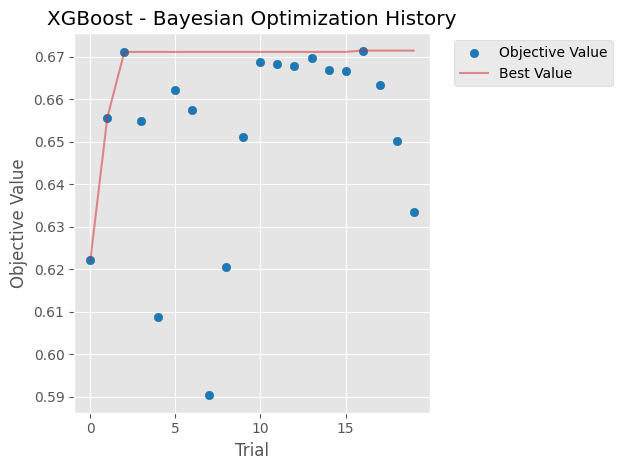


BEST HYPERPARAMETERS PER METHOD
                  GridSearchCV RandomizedSearchCV Optuna TPE
colsample_bylevel            -           0.817078   0.664416
colsample_bytree             -           0.570462   0.595609
gamma                        -           0.401098   0.414773
grow_policy          depthwise          lossguide  lossguide
learning_rate             0.05           0.012886    0.04732
max_depth                    3                  0          0
max_leaves                   -                 14         22
min_child_weight             -                  9         10
n_estimators               150                228        349
reg_alpha                    -           0.006235   8.883621
reg_lambda                   -           0.102576   0.382387
scale_pos_weight           1.0           3.446384   2.162077
subsample                  1.0           0.882743   0.788652

TOP 5 GRID CONFIGURATIONS
                                                                                      

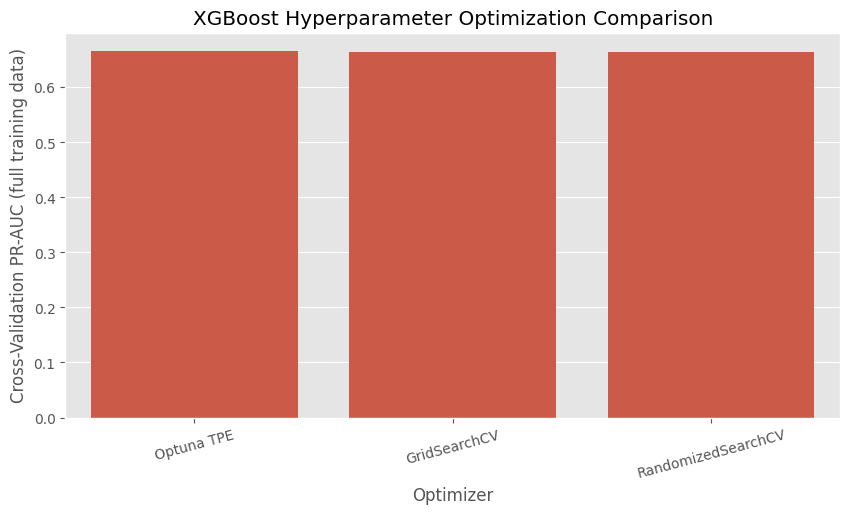

Best XGBoost Optimization Method: Optuna TPE

TEST SET COMPARISON (reporting only, not used for selection)
      Optimization  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
      GridSearchCV    0.8070     0.6723  0.5321    0.5940   0.8453  0.6596
RandomizedSearchCV    0.7289     0.4936  0.8262    0.6180   0.8481  0.6637
        Optuna TPE    0.7686     0.5471  0.7460    0.6312   0.8480  0.6546

Confusion matrix (selected model, test set):
[[804 231]
 [ 95 279]]


In [35]:
# =====================================================================
# XGBoost tuning on Telco Customer Churn: Grid vs Random vs Optuna
# Self-contained: loads data, cleans it, splits, tunes, evaluates.
# =====================================================================
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import optuna.visualization.matplotlib
import xgboost as xgb
from xgboost import XGBClassifier
from scipy.stats import randint, uniform, loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
print("XGBoost version:", xgb.__version__)

# ---------------- CONFIG ----------------
SEARCH_N = 3000     # rows used during the search phase (lower = faster)
N_ITER   = 20       # random-search iterations / Optuna trials
N_SPLITS = 3        # CV folds
SEED     = 42
USE_GPU  = False    # True only if the runtime has a GPU
N_CORES  = os.cpu_count() or 2
# ----------------------------------------

# =================== DATA ===================
DATA_PATH = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not os.path.exists(DATA_PATH):
    hits = glob.glob("/kaggle/input/**/*Telco*Churn*.csv", recursive=True) + \
           glob.glob("./**/*Telco*Churn*.csv", recursive=True)
    if not hits:
        try:                                   # last resort: download via kagglehub
            import kagglehub
            p = kagglehub.dataset_download("blastchar/telco-customer-churn")
            hits = glob.glob(os.path.join(p, "*.csv"))
        except Exception as e:
            raise FileNotFoundError("Telco CSV not found: " + str(e))
    DATA_PATH = hits[0]

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, df.shape)

TARGET = "Churn"
df = df.drop(columns=[c for c in ["customerID"] if c in df.columns])
# TotalCharges has blank strings for new customers -> numeric (NaN gets imputed)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df[TARGET] = (df[TARGET].astype(str).str.strip().str.lower() == "yes").astype(int)

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore",
                                           sparse_output=False))]), cat_cols),
])
print("Train:", X_train.shape, "Test:", X_test.shape,
      "| Churn rate:", round(float(y_train.mean()), 3))

# =================== SETUP ===================
if len(X_train) > SEARCH_N:
    X_search, _, y_search, _ = train_test_split(
        X_train, y_train, train_size=SEARCH_N, stratify=y_train,
        random_state=SEED)
else:
    X_search, y_search = X_train, y_train

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

BASE_XGB = dict(objective="binary:logistic", eval_metric="logloss",
                tree_method="hist", random_state=SEED)
if USE_GPU:
    BASE_XGB["device"] = "cuda"

# n_jobs=1 inside XGBoost; parallelism comes from the CV folds / candidates
xgb_pipeline = Pipeline([("preprocessor", preprocessor),
                         ("xgb", XGBClassifier(n_jobs=1, **BASE_XGB))])


def make_xgb(params, n_jobs):
    return Pipeline([("preprocessor", clone(preprocessor)),
                     ("xgb", XGBClassifier(n_jobs=n_jobs, **BASE_XGB, **params))])


def evaluate(name, model, label_col="Optimization"):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        label_col: name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1 Score":  f1_score(y_test, y_pred),
        "ROC-AUC":   roc_auc_score(y_test, y_prob),
        "PR-AUC":    average_precision_score(y_test, y_prob),
    }


# ================= 0. BASELINE =================
t = time.time()
baseline = make_xgb({}, N_CORES).fit(X_train, y_train)
base_row = evaluate("Baseline XGBoost", baseline, label_col="Model")
base_row["Training Time"] = time.time() - t
print("\nBASELINE")
print(pd.DataFrame([base_row]).round(4).to_string(index=False))

# ================= 1. GRID SEARCH =================
xgb_param_grid = [
    {"xgb__grow_policy": ["depthwise"], "xgb__n_estimators": [150, 300],
     "xgb__max_depth": [3, 5], "xgb__learning_rate": [0.05, 0.1],
     "xgb__subsample": [0.8, 1.0], "xgb__scale_pos_weight": [1.0, 2.5]},   # 32
    {"xgb__grow_policy": ["lossguide"], "xgb__max_depth": [0],
     "xgb__n_estimators": [150, 300], "xgb__max_leaves": [15, 31],
     "xgb__learning_rate": [0.05, 0.1], "xgb__subsample": [0.8, 1.0],
     "xgb__scale_pos_weight": [1.0, 2.5]},                                 # 32
]
xgb_grid = GridSearchCV(xgb_pipeline, xgb_param_grid,
                        scoring="average_precision", cv=cv,
                        n_jobs=-1, refit=False, verbose=0)
t = time.time(); xgb_grid.fit(X_search, y_search)
xgb_grid_time = time.time() - t
xgb_grid_fits = len(xgb_grid.cv_results_["params"]) * N_SPLITS
print("\nGRID SEARCH RESULTS")
print("Best Parameters:", xgb_grid.best_params_)
print("Best CV PR-AUC:", round(xgb_grid.best_score_, 4))
print("Execution Time:", round(xgb_grid_time, 2), "seconds")

# ================= 2. RANDOMIZED SEARCH =================
_shared = {
    "xgb__n_estimators": randint(100, 401),
    "xgb__learning_rate": loguniform(0.01, 0.3),
    "xgb__subsample": uniform(0.6, 0.4),
    "xgb__colsample_bytree": uniform(0.5, 0.5),
    "xgb__colsample_bylevel": uniform(0.6, 0.4),
    "xgb__min_child_weight": randint(1, 11),
    "xgb__gamma": uniform(0, 0.5),
    "xgb__reg_alpha": loguniform(1e-3, 10),
    "xgb__reg_lambda": loguniform(0.1, 10),
    "xgb__scale_pos_weight": uniform(1, 3),
}
xgb_random_space = [
    {**_shared, "xgb__grow_policy": ["depthwise"], "xgb__max_depth": randint(3, 10)},
    {**_shared, "xgb__grow_policy": ["lossguide"], "xgb__max_depth": [0],
     "xgb__max_leaves": randint(8, 64)},
]
xgb_random = RandomizedSearchCV(xgb_pipeline, xgb_random_space, n_iter=N_ITER,
                                scoring="average_precision", cv=cv, n_jobs=-1,
                                random_state=SEED, refit=False, verbose=0)
t = time.time(); xgb_random.fit(X_search, y_search)
xgb_random_time = time.time() - t
xgb_random_fits = N_ITER * N_SPLITS
print("\nRANDOMIZED SEARCH RESULTS")
print("Best Parameters:", xgb_random.best_params_)
print("Best CV PR-AUC:", round(xgb_random.best_score_, 4))
print("Execution Time:", round(xgb_random_time, 2), "seconds")

# ================= 3. OPTUNA (TPE) =================
def xgb_objective(trial):
    gp = trial.suggest_categorical("grow_policy", ["depthwise", "lossguide"])
    p = {
        "grow_policy": gp,
        "n_estimators": trial.suggest_int("n_estimators", 100, 400),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "colsample_bylevel": trial.suggest_float("colsample_bylevel", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0.0, 0.5),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 4.0),
    }
    if gp == "depthwise":
        p["max_depth"] = trial.suggest_int("max_depth", 3, 9)
    else:
        p["max_depth"] = 0
        p["max_leaves"] = trial.suggest_int("max_leaves", 8, 63)
    trial.set_user_attr("model_params", p)
    return cross_val_score(make_xgb(p, 1), X_search, y_search,
                           scoring="average_precision", cv=cv,
                           n_jobs=N_SPLITS).mean()

study_xgb = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
t = time.time(); study_xgb.optimize(xgb_objective, n_trials=N_ITER)
xgb_optuna_time = time.time() - t
xgb_optuna_fits = len(study_xgb.trials) * N_SPLITS
optuna_best_model_params = study_xgb.best_trial.user_attrs["model_params"]
print("\nOPTUNA RESULTS")
print("Best Parameters:", optuna_best_model_params)
print("Best CV PR-AUC:", round(study_xgb.best_value, 4))
print("Execution Time:", round(xgb_optuna_time, 2), "seconds")

optuna.visualization.matplotlib.plot_optimization_history(study_xgb)
plt.title("XGBoost - Bayesian Optimization History")
plt.show()

# ================= BEST PARAMETERS SUMMARY =================
strip = lambda d: {k.replace("xgb__", ""): v for k, v in d.items()}
best_params_table = pd.DataFrame({
    "GridSearchCV":       pd.Series(strip(xgb_grid.best_params_)),
    "RandomizedSearchCV": pd.Series(strip(xgb_random.best_params_)),
    "Optuna TPE":         pd.Series(optuna_best_model_params),
}).fillna("-")
print("\nBEST HYPERPARAMETERS PER METHOD")
print(best_params_table.to_string())

for name, s in [("GRID", xgb_grid), ("RANDOM", xgb_random)]:
    top = (pd.DataFrame(s.cv_results_)
           .sort_values("mean_test_score", ascending=False)
           [["params", "mean_test_score", "std_test_score", "mean_fit_time"]]
           .head(5))
    print(f"\nTOP 5 {name} CONFIGURATIONS")
    print(top.to_string(index=False))

try:
    imp = optuna.importance.get_param_importances(study_xgb)
    print("\nOPTUNA HYPERPARAMETER IMPORTANCE")
    for k, v in imp.items():
        print(f"{k:20s} {v:.3f}")
except Exception as e:
    print("Importance skipped:", e)

# ================= FAIR RE-SCORE ON FULL TRAINING DATA (CV only) =================
def build_xgb(params, n_jobs):
    m = clone(xgb_pipeline)
    m.set_params(**params)
    m.set_params(xgb__n_jobs=n_jobs)
    return m

optuna_xgb_params = {f"xgb__{k}": v for k, v in optuna_best_model_params.items()}
candidate_params = {
    "GridSearchCV":       xgb_grid.best_params_,
    "RandomizedSearchCV": xgb_random.best_params_,
    "Optuna TPE":         optuna_xgb_params,
}
full_cv_scores = {
    n: cross_val_score(build_xgb(p, 1), X_train, y_train,
                       scoring="average_precision", cv=cv,
                       n_jobs=N_SPLITS).mean()
    for n, p in candidate_params.items()
}

# ================= SEARCH COMPARISON =================
xgb_optimization_results = pd.DataFrame([
    {"Optimizer": "GridSearchCV", "Search CV PR-AUC": xgb_grid.best_score_,
     "Full-data CV PR-AUC": full_cv_scores["GridSearchCV"],
     "Execution Time": xgb_grid_time, "Number of Fits": xgb_grid_fits},
    {"Optimizer": "RandomizedSearchCV", "Search CV PR-AUC": xgb_random.best_score_,
     "Full-data CV PR-AUC": full_cv_scores["RandomizedSearchCV"],
     "Execution Time": xgb_random_time, "Number of Fits": xgb_random_fits},
    {"Optimizer": "Optuna TPE", "Search CV PR-AUC": study_xgb.best_value,
     "Full-data CV PR-AUC": full_cv_scores["Optuna TPE"],
     "Execution Time": xgb_optuna_time, "Number of Fits": xgb_optuna_fits},
]).sort_values("Full-data CV PR-AUC", ascending=False).reset_index(drop=True)

print("\nXGBOOST OPTIMIZATION COMPARISON")
print(xgb_optimization_results.round(4).to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=xgb_optimization_results, x="Optimizer", y="Full-data CV PR-AUC")
plt.title("XGBoost Hyperparameter Optimization Comparison")
plt.ylabel("Cross-Validation PR-AUC (full training data)")
plt.xticks(rotation=15)
plt.show()

best_xgb_method = xgb_optimization_results.iloc[0]["Optimizer"]
print("Best XGBoost Optimization Method:", best_xgb_method)

# ================= FINAL MODELS (refit on FULL training data) =================
best_grid_xgb   = build_xgb(xgb_grid.best_params_, N_CORES).fit(X_train, y_train)
best_random_xgb = build_xgb(xgb_random.best_params_, N_CORES).fit(X_train, y_train)
best_optuna_xgb = build_xgb(optuna_xgb_params, N_CORES).fit(X_train, y_train)

xgb_test_comparison = pd.DataFrame([
    evaluate("GridSearchCV",       best_grid_xgb),
    evaluate("RandomizedSearchCV", best_random_xgb),
    evaluate("Optuna TPE",         best_optuna_xgb),
])
print("\nTEST SET COMPARISON (reporting only, not used for selection)")
print(xgb_test_comparison.round(4).to_string(index=False))

best_xgb_model = {
    "GridSearchCV": best_grid_xgb,
    "RandomizedSearchCV": best_random_xgb,
    "Optuna TPE": best_optuna_xgb,
}[best_xgb_method]

print("\nConfusion matrix (selected model, test set):")
print(confusion_matrix(y_test, best_xgb_model.predict(X_test)))

In [36]:
# =====================================================================
# CatBoost tuning on Telco Customer Churn: Grid vs Random vs Optuna (Fixed)
# =====================================================================
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import optuna.visualization.matplotlib
import catboost as cb
from catboost import CatBoostClassifier
from scipy.stats import randint, uniform, loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
print("CatBoost version:", cb.__version__)

# ---------------- CONFIG ----------------
SEARCH_N = 3000     # rows used during search phase
N_ITER   = 20       # random-search iterations / Optuna trials
N_SPLITS = 3        # CV folds
SEED     = 42
USE_GPU  = False    # True if GPU runtime is active
N_CORES  = os.cpu_count() or 2
# ----------------------------------------

# Helper to convert numpy types to native python types for sklearn compatibility
def clean_params(params):
    return {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}

# =================== DATA ===================
DATA_PATH = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not os.path.exists(DATA_PATH):
    hits = glob.glob("/kaggle/input/**/*Telco*Churn*.csv", recursive=True) + \
           glob.glob("./**/*Telco*Churn*.csv", recursive=True)
    if not hits:
        import kagglehub
        p = kagglehub.dataset_download("blastchar/telco-customer-churn")
        hits = glob.glob(os.path.join(p, "*.csv"))
    DATA_PATH = hits[0]

df = pd.read_csv(DATA_PATH)
TARGET = "Churn"
df = df.drop(columns=[c for c in ["customerID"] if c in df.columns])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df[TARGET] = (df[TARGET].astype(str).str.strip().str.lower() == "yes").astype(int)

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore",
                                           sparse_output=False))]), cat_cols),
])

if len(X_train) > SEARCH_N:
    X_search, _, y_search, _ = train_test_split(
        X_train, y_train, train_size=SEARCH_N, stratify=y_train, random_state=SEED)
else:
    X_search, y_search = X_train, y_train

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

BASE_CB = dict(loss_function="Logloss", verbose=0, random_seed=SEED, thread_count=1)
if USE_GPU:
    BASE_CB["task_type"] = "GPU"

cat_pipeline = Pipeline([("preprocessor", preprocessor),
                         ("catboost", CatBoostClassifier(**BASE_CB))])

def make_cat(params, threads):
    p = BASE_CB.copy()
    p["thread_count"] = threads
    p.update(clean_params(params))
    return Pipeline([("preprocessor", clone(preprocessor)),
                     ("catboost", CatBoostClassifier(**p))])

def evaluate(name, model, label_col="Optimization"):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        label_col: name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1 Score":  f1_score(y_test, y_pred),
        "ROC-AUC":   roc_auc_score(y_test, y_prob),
        "PR-AUC":    average_precision_score(y_test, y_prob),
    }

# ================= 0. BASELINE =================
t = time.time()
baseline = make_cat({}, N_CORES).fit(X_train, y_train)
base_row = evaluate("Baseline CatBoost", baseline, label_col="Model")
base_row["Training Time"] = time.time() - t
print("\nBASELINE")
print(pd.DataFrame([base_row]).round(4).to_string(index=False))

# ================= 1. GRID SEARCH =================
cat_param_grid = {
    "catboost__iterations": [200, 400],
    "catboost__depth": [4, 6],
    "catboost__learning_rate": [0.05, 0.1],
    "catboost__l2_leaf_reg": [1, 3],
}
cat_grid = GridSearchCV(cat_pipeline, cat_param_grid,
                        scoring="average_precision", cv=cv,
                        n_jobs=-1, refit=False, verbose=0)
t = time.time(); cat_grid.fit(X_search, y_search)
cat_grid_time = time.time() - t
cat_grid_fits = len(cat_grid.cv_results_["params"]) * N_SPLITS
print("\nGRID SEARCH RESULTS")
print("Best Parameters:", clean_params(cat_grid.best_params_))
print("Best CV PR-AUC:", round(cat_grid.best_score_, 4))
print("Execution Time:", round(cat_grid_time, 2), "seconds")

# ================= 2. RANDOMIZED SEARCH =================
cat_random_space = {
    "catboost__iterations": randint(150, 500),
    "catboost__depth": randint(3, 9),
    "catboost__learning_rate": loguniform(0.01, 0.3),
    "catboost__l2_leaf_reg": uniform(1, 10),
    "catboost__subsample": uniform(0.6, 0.4),
}
cat_random = RandomizedSearchCV(cat_pipeline, cat_random_space, n_iter=N_ITER,
                                scoring="average_precision", cv=cv, n_jobs=-1,
                                random_state=SEED, refit=False, verbose=0)
t = time.time(); cat_random.fit(X_search, y_search)
cat_random_time = time.time() - t
cat_random_fits = N_ITER * N_SPLITS
print("\nRANDOMIZED SEARCH RESULTS")
print("Best Parameters:", clean_params(cat_random.best_params_))
print("Best CV PR-AUC:", round(cat_random.best_score_, 4))
print("Execution Time:", round(cat_random_time, 2), "seconds")

# ================= 3. OPTUNA (TPE) =================
def cat_objective(trial):
    p = {
        "iterations": trial.suggest_int("iterations", 150, 500),
        "depth": trial.suggest_int("depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
    }
    trial.set_user_attr("model_params", p)
    return cross_val_score(make_cat(p, 1), X_search, y_search,
                           scoring="average_precision", cv=cv,
                           n_jobs=N_SPLITS).mean()

study_cat = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
t = time.time(); study_cat.optimize(cat_objective, n_trials=N_ITER)
cat_optuna_time = time.time() - t
cat_optuna_fits = len(study_cat.trials) * N_SPLITS
optuna_best_cat_params = study_cat.best_trial.user_attrs["model_params"]
print("\nOPTUNA RESULTS")
print("Best Parameters:", clean_params(optuna_best_cat_params))
print("Best CV PR-AUC:", round(study_cat.best_value, 4))
print("Execution Time:", round(cat_optuna_time, 2), "seconds")

# ================= COMPARISON & FINAL FIT =================
optuna_cat_params = {f"catboost__{k}": v for k, v in optuna_best_cat_params.items()}

candidate_params_cat = {
    "GridSearchCV":       clean_params(cat_grid.best_params_),
    "RandomizedSearchCV": clean_params(cat_random.best_params_),
    "Optuna TPE":         clean_params(optuna_cat_params),
}

full_cv_scores_cat = {
    n: cross_val_score(make_cat({k.replace("catboost__", ""): v for k, v in p.items()}, 1),
                       X_train, y_train, scoring="average_precision", cv=cv, n_jobs=N_SPLITS).mean()
    for n, p in candidate_params_cat.items()
}

cat_optimization_results = pd.DataFrame([
    {"Optimizer": "GridSearchCV", "Search CV PR-AUC": cat_grid.best_score_,
     "Full-data CV PR-AUC": full_cv_scores_cat["GridSearchCV"],
     "Execution Time": cat_grid_time, "Number of Fits": cat_grid_fits},
    {"Optimizer": "RandomizedSearchCV", "Search CV PR-AUC": cat_random.best_score_,
     "Full-data CV PR-AUC": full_cv_scores_cat["RandomizedSearchCV"],
     "Execution Time": cat_random_time, "Number of Fits": cat_random_fits},
    {"Optimizer": "Optuna TPE", "Search CV PR-AUC": study_cat.best_value,
     "Full-data CV PR-AUC": full_cv_scores_cat["Optuna TPE"],
     "Execution Time": cat_optuna_time, "Number of Fits": cat_optuna_fits},
]).sort_values("Full-data CV PR-AUC", ascending=False).reset_index(drop=True)

print("\nCATBOOST OPTIMIZATION COMPARISON")
print(cat_optimization_results.round(4).to_string(index=False))

best_cat_method = cat_optimization_results.iloc[0]["Optimizer"]
best_cat_model = make_cat({k.replace("catboost__", ""): v for k, v in candidate_params_cat[best_cat_method].items()}, N_CORES).fit(X_train, y_train)
print("\nTest Evaluation for Best CatBoost Method:")
print(pd.DataFrame([evaluate(best_cat_method, best_cat_model)]).round(4).to_string(index=False))

CatBoost version: 1.2.10

BASELINE
            Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC  Training Time
Baseline CatBoost    0.7928     0.6331  0.5214    0.5718   0.8377  0.6471         3.5054

GRID SEARCH RESULTS
Best Parameters: {'catboost__depth': 4, 'catboost__iterations': 200, 'catboost__l2_leaf_reg': 1, 'catboost__learning_rate': 0.05}
Best CV PR-AUC: 0.664
Execution Time: 13.8 seconds

RANDOMIZED SEARCH RESULTS
Best Parameters: {'catboost__depth': 6, 'catboost__iterations': 151, 'catboost__l2_leaf_reg': 5.2515587449124475, 'catboost__learning_rate': 0.02028406763400795, 'catboost__subsample': 0.8270801311279966}
Best CV PR-AUC: 0.6696
Execution Time: 27.41 seconds

OPTUNA RESULTS
Best Parameters: {'iterations': 296, 'depth': 5, 'learning_rate': 0.020539891225990273, 'l2_leaf_reg': 8.98465223279884, 'subsample': 0.8641489910837626}
Best CV PR-AUC: 0.6724
Execution Time: 22.27 seconds

CATBOOST OPTIMIZATION COMPARISON
         Optimizer  Search CV PR-AUC  Full-

LightGBM version: 4.6.0
Loaded: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv (7043, 21)
Train: (5634, 19) Test: (1409, 19) | Churn rate: 0.265

BASELINE
            Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC  Training Time
Baseline LightGBM    0.7885     0.6226   0.516    0.5643   0.8323  0.6347         0.2577

GRID SEARCH RESULTS
Best Parameters: {'lgbm__learning_rate': 0.05, 'lgbm__max_depth': 3, 'lgbm__n_estimators': 150, 'lgbm__num_leaves': 15, 'lgbm__scale_pos_weight': 1.0, 'lgbm__subsample': 0.8}
Best CV PR-AUC: 0.6607
Execution Time: 19.62 seconds

RANDOMIZED SEARCH RESULTS
Best Parameters: {'lgbm__colsample_bytree': 0.7247253370691017, 'lgbm__learning_rate': 0.013833507535062186, 'lgbm__max_depth': 9, 'lgbm__min_child_samples': 32, 'lgbm__n_estimators': 161, 'lgbm__num_leaves': 38, 'lgbm__reg_alpha': 0.4609877941534894, 'lgbm__reg_lambda': 1.5226341829186323, 'lgbm__scale_pos_weight': 1.8241653789701924, 'lgbm__su

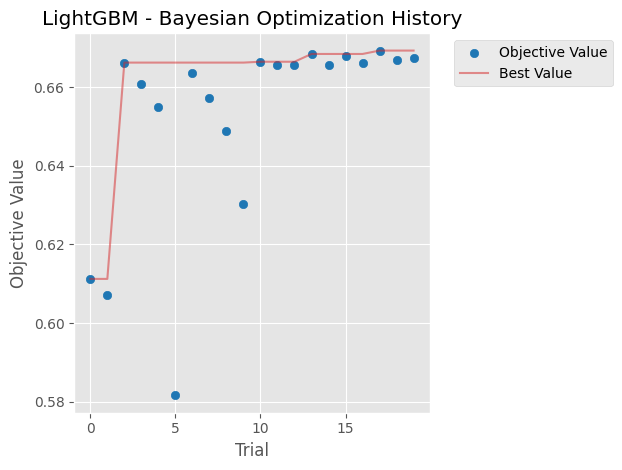


BEST HYPERPARAMETERS PER METHOD
                  GridSearchCV  RandomizedSearchCV  Optuna TPE
colsample_bytree             -            0.724725    0.585485
learning_rate             0.05            0.013834    0.013336
max_depth                  3.0            9.000000    4.000000
min_child_samples            -           32.000000   35.000000
n_estimators             150.0          161.000000  351.000000
num_leaves                15.0           38.000000   37.000000
reg_alpha                    -            0.460988    0.720577
reg_lambda                   -            1.522634    5.559569
scale_pos_weight           1.0            1.824165    1.665427
subsample                  0.8            0.824497    0.757805
subsample_freq               -            1.000000    1.000000

LIGHTGBM OPTIMIZATION COMPARISON
         Optimizer  Search CV PR-AUC  Full-data CV PR-AUC  Execution Time  Number of Fits
        Optuna TPE            0.6693               0.6703          6.3448              

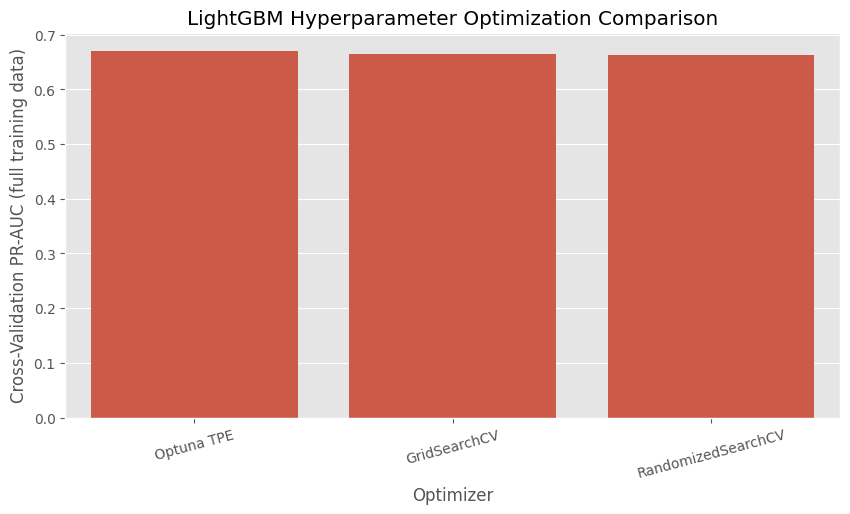

Best LightGBM Optimization Method: Optuna TPE

TEST SET COMPARISON (reporting only, not used for selection)
      Optimization  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
      GridSearchCV    0.8062     0.6735  0.5241    0.5895   0.8455  0.6601
RandomizedSearchCV    0.7857     0.5849  0.6631    0.6216   0.8467  0.6592
        Optuna TPE    0.7885     0.5848  0.7005    0.6375   0.8486  0.6630

Confusion matrix (selected model, test set):
[[849 186]
 [112 262]]


In [37]:
# =====================================================================
# LightGBM tuning on Telco Customer Churn: Grid vs Random vs Optuna
# Self-contained: loads data, cleans it, splits, tunes, evaluates.
# =====================================================================
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import optuna.visualization.matplotlib
import lightgbm as lgb
from lightgbm import LGBMClassifier
from scipy.stats import randint, uniform, loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
print("LightGBM version:", lgb.__version__)

# ---------------- CONFIG ----------------
SEARCH_N = 3000     # rows used during search phase
N_ITER   = 20       # random-search iterations / Optuna trials
N_SPLITS = 3        # CV folds
SEED     = 42
USE_GPU  = False    # True if GPU runtime is active
N_CORES  = os.cpu_count() or 2
# ----------------------------------------

# Helper to convert numpy scalars to native Python types for sklearn clone()
def clean_params(params):
    return {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}

# =================== DATA ===================
DATA_PATH = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not os.path.exists(DATA_PATH):
    hits = glob.glob("/kaggle/input/**/*Telco*Churn*.csv", recursive=True) + \
           glob.glob("./**/*Telco*Churn*.csv", recursive=True)
    if not hits:
        import kagglehub
        p = kagglehub.dataset_download("blastchar/telco-customer-churn")
        hits = glob.glob(os.path.join(p, "*.csv"))
    DATA_PATH = hits[0]

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, df.shape)

TARGET = "Churn"
df = df.drop(columns=[c for c in ["customerID"] if c in df.columns])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df[TARGET] = (df[TARGET].astype(str).str.strip().str.lower() == "yes").astype(int)

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

# Native pandas output keeps valid feature names for LightGBM without warnings
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), cat_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

print("Train:", X_train.shape, "Test:", X_test.shape,
      "| Churn rate:", round(float(y_train.mean()), 3))

# =================== SETUP ===================
if len(X_train) > SEARCH_N:
    X_search, _, y_search, _ = train_test_split(
        X_train, y_train, train_size=SEARCH_N, stratify=y_train, random_state=SEED)
else:
    X_search, y_search = X_train, y_train

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

BASE_LGB = dict(
    objective="binary",
    metric="binary_logloss",
    random_state=SEED,
    verbose=-1,
)
if USE_GPU:
    BASE_LGB["device"] = "gpu"

lgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("lgbm", LGBMClassifier(n_jobs=1, **BASE_LGB))
])

def make_lgb(params, n_jobs):
    p = BASE_LGB.copy()
    p["n_jobs"] = n_jobs
    p.update(clean_params(params))
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("lgbm", LGBMClassifier(**p))
    ])

def evaluate(name, model, label_col="Optimization"):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        label_col: name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1 Score":  f1_score(y_test, y_pred),
        "ROC-AUC":   roc_auc_score(y_test, y_prob),
        "PR-AUC":    average_precision_score(y_test, y_prob),
    }

# ================= 0. BASELINE =================
t = time.time()
baseline = make_lgb({}, N_CORES).fit(X_train, y_train)
base_row = evaluate("Baseline LightGBM", baseline, label_col="Model")
base_row["Training Time"] = time.time() - t
print("\nBASELINE")
print(pd.DataFrame([base_row]).round(4).to_string(index=False))

# ================= 1. GRID SEARCH =================
lgb_param_grid = {
    "lgbm__n_estimators": [150, 300],
    "lgbm__max_depth": [3, 5],
    "lgbm__learning_rate": [0.05, 0.1],
    "lgbm__num_leaves": [15, 31],
    "lgbm__subsample": [0.8, 1.0],
    "lgbm__scale_pos_weight": [1.0, 2.5],
}
lgb_grid = GridSearchCV(lgb_pipeline, lgb_param_grid,
                        scoring="average_precision", cv=cv,
                        n_jobs=-1, refit=False, verbose=0)
t = time.time()
lgb_grid.fit(X_search, y_search)
lgb_grid_time = time.time() - t
lgb_grid_fits = len(lgb_grid.cv_results_["params"]) * N_SPLITS
print("\nGRID SEARCH RESULTS")
print("Best Parameters:", clean_params(lgb_grid.best_params_))
print("Best CV PR-AUC:", round(lgb_grid.best_score_, 4))
print("Execution Time:", round(lgb_grid_time, 2), "seconds")

# ================= 2. RANDOMIZED SEARCH =================
lgb_random_space = {
    "lgbm__n_estimators": randint(100, 401),
    "lgbm__learning_rate": loguniform(0.01, 0.3),
    "lgbm__num_leaves": randint(15, 64),
    "lgbm__max_depth": randint(3, 10),
    "lgbm__min_child_samples": randint(10, 51),
    "lgbm__subsample": uniform(0.6, 0.4),
    "lgbm__subsample_freq": [1],
    "lgbm__colsample_bytree": uniform(0.5, 0.5),
    "lgbm__reg_alpha": loguniform(1e-3, 10),
    "lgbm__reg_lambda": loguniform(0.1, 10),
    "lgbm__scale_pos_weight": uniform(1.0, 3.0),
}
lgb_random = RandomizedSearchCV(lgb_pipeline, lgb_random_space, n_iter=N_ITER,
                                scoring="average_precision", cv=cv, n_jobs=-1,
                                random_state=SEED, refit=False, verbose=0)
t = time.time()
lgb_random.fit(X_search, y_search)
lgb_random_time = time.time() - t
lgb_random_fits = N_ITER * N_SPLITS
print("\nRANDOMIZED SEARCH RESULTS")
print("Best Parameters:", clean_params(lgb_random.best_params_))
print("Best CV PR-AUC:", round(lgb_random.best_score_, 4))
print("Execution Time:", round(lgb_random_time, 2), "seconds")

# ================= 3. OPTUNA (TPE) =================
def lgb_objective(trial):
    p = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 400),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 63),
        "max_depth": trial.suggest_int("max_depth", 3, 9),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 50),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 4.0),
    }
    trial.set_user_attr("model_params", p)
    return cross_val_score(make_lgb(p, 1), X_search, y_search,
                           scoring="average_precision", cv=cv,
                           n_jobs=N_SPLITS).mean()

study_lgb = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
t = time.time()
study_lgb.optimize(lgb_objective, n_trials=N_ITER)
lgb_optuna_time = time.time() - t
lgb_optuna_fits = len(study_lgb.trials) * N_SPLITS
optuna_best_lgb_params = clean_params(study_lgb.best_trial.user_attrs["model_params"])
print("\nOPTUNA RESULTS")
print("Best Parameters:", optuna_best_lgb_params)
print("Best CV PR-AUC:", round(study_lgb.best_value, 4))
print("Execution Time:", round(lgb_optuna_time, 2), "seconds")

optuna.visualization.matplotlib.plot_optimization_history(study_lgb)
plt.title("LightGBM - Bayesian Optimization History")
plt.show()

# ================= BEST PARAMETERS SUMMARY =================
strip = lambda d: {k.replace("lgbm__", ""): v for k, v in clean_params(d).items()}
best_params_table = pd.DataFrame({
    "GridSearchCV":       pd.Series(strip(lgb_grid.best_params_)),
    "RandomizedSearchCV": pd.Series(strip(lgb_random.best_params_)),
    "Optuna TPE":         pd.Series(optuna_best_lgb_params),
}).fillna("-")
print("\nBEST HYPERPARAMETERS PER METHOD")
print(best_params_table.to_string())

# ================= FAIR RE-SCORE ON FULL TRAINING DATA (CV only) =================
optuna_lgb_params = {f"lgbm__{k}": v for k, v in optuna_best_lgb_params.items()}
candidate_params_lgb = {
    "GridSearchCV":       clean_params(lgb_grid.best_params_),
    "RandomizedSearchCV": clean_params(lgb_random.best_params_),
    "Optuna TPE":         clean_params(optuna_lgb_params),
}

full_cv_scores_lgb = {
    n: cross_val_score(make_lgb({k.replace("lgbm__", ""): v for k, v in p.items()}, 1),
                       X_train, y_train, scoring="average_precision", cv=cv, n_jobs=N_SPLITS).mean()
    for n, p in candidate_params_lgb.items()
}

# ================= SEARCH COMPARISON =================
lgb_optimization_results = pd.DataFrame([
    {"Optimizer": "GridSearchCV", "Search CV PR-AUC": lgb_grid.best_score_,
     "Full-data CV PR-AUC": full_cv_scores_lgb["GridSearchCV"],
     "Execution Time": lgb_grid_time, "Number of Fits": lgb_grid_fits},
    {"Optimizer": "RandomizedSearchCV", "Search CV PR-AUC": lgb_random.best_score_,
     "Full-data CV PR-AUC": full_cv_scores_lgb["RandomizedSearchCV"],
     "Execution Time": lgb_random_time, "Number of Fits": lgb_random_fits},
    {"Optimizer": "Optuna TPE", "Search CV PR-AUC": study_lgb.best_value,
     "Full-data CV PR-AUC": full_cv_scores_lgb["Optuna TPE"],
     "Execution Time": lgb_optuna_time, "Number of Fits": lgb_optuna_fits},
]).sort_values("Full-data CV PR-AUC", ascending=False).reset_index(drop=True)

print("\nLIGHTGBM OPTIMIZATION COMPARISON")
print(lgb_optimization_results.round(4).to_string(index=False))

plt.figure(figsize=(10, 5))
sns.barplot(data=lgb_optimization_results, x="Optimizer", y="Full-data CV PR-AUC")
plt.title("LightGBM Hyperparameter Optimization Comparison")
plt.ylabel("Cross-Validation PR-AUC (full training data)")
plt.xticks(rotation=15)
plt.show()

best_lgb_method = lgb_optimization_results.iloc[0]["Optimizer"]
print("Best LightGBM Optimization Method:", best_lgb_method)

# ================= FINAL MODELS (refit on FULL training data) =================
best_grid_lgb   = make_lgb(strip(lgb_grid.best_params_), N_CORES).fit(X_train, y_train)
best_random_lgb = make_lgb(strip(lgb_random.best_params_), N_CORES).fit(X_train, y_train)
best_optuna_lgb = make_lgb(optuna_best_lgb_params, N_CORES).fit(X_train, y_train)

lgb_test_comparison = pd.DataFrame([
    evaluate("GridSearchCV",       best_grid_lgb),
    evaluate("RandomizedSearchCV", best_random_lgb),
    evaluate("Optuna TPE",         best_optuna_lgb),
])
print("\nTEST SET COMPARISON (reporting only, not used for selection)")
print(lgb_test_comparison.round(4).to_string(index=False))

best_lgb_model = {
    "GridSearchCV": best_grid_lgb,
    "RandomizedSearchCV": best_random_lgb,
    "Optuna TPE": best_optuna_lgb,
}[best_lgb_method]

print("\nConfusion matrix (selected model, test set):")
print(confusion_matrix(y_test, best_lgb_model.predict(X_test)))

In [38]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             brier_score_loss, log_loss)

warnings.filterwarnings("ignore")
SEED = 42

# =================== DATA (same loader as the LightGBM script) ===================
DATA_PATH = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not os.path.exists(DATA_PATH):
    hits = glob.glob("/kaggle/input/**/*Telco*Churn*.csv", recursive=True) + \
           glob.glob("./**/*Telco*Churn*.csv", recursive=True)
    if not hits:
        import kagglehub
        p = kagglehub.dataset_download("blastchar/telco-customer-churn")
        hits = glob.glob(os.path.join(p, "*.csv"))
    DATA_PATH = hits[0]

df = pd.read_csv(DATA_PATH)
df = df.drop(columns=[c for c in ["customerID"] if c in df.columns])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = (df["Churn"].astype(str).str.strip().str.lower() == "yes").astype(int)

X, y = df.drop(columns=["Churn"]), df["Churn"]

# Same first split as the LightGBM script (this X_test is the old, already-inspected test set)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# Development / final-holdout split carved out of X_train
X_dev, X_final, y_dev, y_final = train_test_split(
    X_train, y_train, test_size=0.20, random_state=2026, stratify=y_train)
print("Dev:", X_dev.shape, "| Final holdout:", X_final.shape,
      "| Churn rate (dev):", round(float(y_dev.mean()), 4))

# =================== PREPROCESSING ===================
numeric_features = X_dev.select_dtypes(include="number").columns.tolist()
categorical_features = X_dev.select_dtypes(exclude="number").columns.tolist()

def create_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                   sparse_output=False))]), categorical_features),
    ])

# =================== TUNED MODELS ===================
svm_model = CalibratedClassifierCV(
    estimator=Pipeline([("preprocessor", create_preprocessor()),
                        ("classifier", SVC(C=0.02117260546317316, kernel="linear",
                                           class_weight="balanced", random_state=SEED))]),
    method="sigmoid", cv=3)

rf_model = Pipeline([("preprocessor", create_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=216, max_depth=10, min_samples_split=8, min_samples_leaf=4,
        max_features=0.5, max_samples=0.7591, criterion="entropy", bootstrap=True,
        class_weight="balanced_subsample", random_state=SEED, n_jobs=-1))])

xgb_model = Pipeline([("preprocessor", create_preprocessor()),
    ("classifier", XGBClassifier(
        n_estimators=349, learning_rate=0.0473, subsample=0.7887, min_child_weight=10,
        gamma=0.4148, scale_pos_weight=2.1621, max_depth=0, max_leaves=22,
        grow_policy="lossguide", tree_method="hist", objective="binary:logistic",
        eval_metric="logloss", random_state=SEED, n_jobs=-1))])

cat_model = Pipeline([("preprocessor", create_preprocessor()),
    ("classifier", CatBoostClassifier(
        iterations=296, depth=5, learning_rate=0.0205399, l2_leaf_reg=8.98465,
        subsample=0.86415, bootstrap_type="Bernoulli", loss_function="Logloss",
        verbose=0, random_seed=SEED, thread_count=-1, allow_writing_files=False))])

lgbm_model = Pipeline([("preprocessor", create_preprocessor()),
    ("classifier", LGBMClassifier(
        n_estimators=351, learning_rate=0.0133361, num_leaves=37, max_depth=4,
        min_child_samples=35, subsample=0.7578049, subsample_freq=1,
        colsample_bytree=0.5854853, reg_alpha=0.7205769, reg_lambda=5.559568,
        scale_pos_weight=1.665427, objective="binary", random_state=SEED,
        verbosity=-1, n_jobs=-1))])

models = {"SVM": svm_model, "Random Forest": rf_model, "XGBoost": xgb_model,
          "CatBoost": cat_model, "LightGBM": lgbm_model}

# =================== OOF PREDICTIONS ===================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_predictions, oof_results = {}, []

for name, model in models.items():
    t0 = time.time()
    p = cross_val_predict(model, X_dev, y_dev, cv=cv,
                          method="predict_proba", n_jobs=1)[:, 1]
    elapsed = time.time() - t0
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all(), f"Bad probabilities: {name}"

    oof_predictions[name] = p
    oof_results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_dev, p),
        "ROC-AUC": roc_auc_score(y_dev, p),
        "Brier Score": brier_score_loss(y_dev, p),
        "Log Loss": log_loss(y_dev, p),
        "Time (s)": elapsed,
    })
    print(f"{name:14s} PR-AUC={oof_results[-1]['PR-AUC']:.4f}  time={elapsed:.1f}s")

oof_results_df = (pd.DataFrame(oof_results)
                  .sort_values("PR-AUC", ascending=False).reset_index(drop=True))
print("\n", oof_results_df.round(4).to_string(index=False))

# =================== SAVE ===================
oof_df = pd.DataFrame(oof_predictions)[list(models.keys())]
oof_df["y_true"] = np.asarray(y_dev)
oof_df.to_csv("oof_predictions.csv", index=False)
print("\nSaved oof_predictions.csv", oof_df.shape)

Dev: (4507, 19) | Final holdout: (1127, 19) | Churn rate (dev): 0.2654
SVM            PR-AUC=0.6585  time=5.7s
Random Forest  PR-AUC=0.6716  time=5.8s
XGBoost        PR-AUC=0.6407  time=2.7s
CatBoost       PR-AUC=0.6744  time=3.1s
LightGBM       PR-AUC=0.6745  time=1.3s

         Model  PR-AUC  ROC-AUC  Brier Score  Log Loss  Time (s)
     LightGBM  0.6745   0.8506       0.1391    0.4254    1.3325
     CatBoost  0.6744   0.8508       0.1326    0.4091    3.0754
Random Forest  0.6716   0.8450       0.1460    0.4423    5.7532
          SVM  0.6585   0.8432       0.1379    0.4247    5.6509
      XGBoost  0.6407   0.8308       0.1538    0.4673    2.6664

Saved oof_predictions.csv (4507, 6)


In [39]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

warnings.filterwarnings("ignore")
SEED = 42


def build_oof():
    """Runs only if no OOF predictions exist in the session or on disk."""
    from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler, OneHotEncoder
    from sklearn.impute import SimpleImputer
    from sklearn.svm import SVC
    from sklearn.calibration import CalibratedClassifierCV
    from sklearn.ensemble import RandomForestClassifier
    from xgboost import XGBClassifier
    from catboost import CatBoostClassifier
    from lightgbm import LGBMClassifier

    DATA_PATH = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
    if not os.path.exists(DATA_PATH):
        hits = glob.glob("/kaggle/input/**/*Telco*Churn*.csv", recursive=True) + \
               glob.glob("./**/*Telco*Churn*.csv", recursive=True)
        if not hits:
            import kagglehub
            p = kagglehub.dataset_download("blastchar/telco-customer-churn")
            hits = glob.glob(os.path.join(p, "*.csv"))
        DATA_PATH = hits[0]

    df = pd.read_csv(DATA_PATH)
    df = df.drop(columns=[c for c in ["customerID"] if c in df.columns])
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["Churn"] = (df["Churn"].astype(str).str.strip().str.lower() == "yes").astype(int)
    X, y = df.drop(columns=["Churn"]), df["Churn"]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    X_dev, X_final, y_dev, y_final = train_test_split(X_train, y_train, test_size=0.20,
                                                      random_state=2026, stratify=y_train)
    print("Dev:", X_dev.shape, "| Final holdout:", X_final.shape,
          "| Churn rate (dev):", round(float(y_dev.mean()), 4))

    num_f = X_dev.select_dtypes(include="number").columns.tolist()
    cat_f = X_dev.select_dtypes(exclude="number").columns.tolist()

    def pre():
        return ColumnTransformer([
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("scaler", StandardScaler())]), num_f),
            ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_f)])

    models = {
        "SVM": CalibratedClassifierCV(
            estimator=Pipeline([("preprocessor", pre()),
                                ("classifier", SVC(C=0.02117260546317316, kernel="linear",
                                                   class_weight="balanced", random_state=SEED))]),
            method="sigmoid", cv=3),
        "Random Forest": Pipeline([("preprocessor", pre()), ("classifier", RandomForestClassifier(
            n_estimators=216, max_depth=10, min_samples_split=8, min_samples_leaf=4, max_features=0.5,
            max_samples=0.7591, criterion="entropy", bootstrap=True, class_weight="balanced_subsample",
            random_state=SEED, n_jobs=-1))]),
        "XGBoost": Pipeline([("preprocessor", pre()), ("classifier", XGBClassifier(
            n_estimators=349, learning_rate=0.0473, subsample=0.7887, min_child_weight=10, gamma=0.4148,
            scale_pos_weight=2.1621, max_depth=0, max_leaves=22, grow_policy="lossguide",
            tree_method="hist", objective="binary:logistic", eval_metric="logloss",
            random_state=SEED, n_jobs=-1))]),
        "CatBoost": Pipeline([("preprocessor", pre()), ("classifier", CatBoostClassifier(
            iterations=296, depth=5, learning_rate=0.0205399, l2_leaf_reg=8.98465, subsample=0.86415,
            bootstrap_type="Bernoulli", loss_function="Logloss", verbose=0, random_seed=SEED,
            thread_count=-1, allow_writing_files=False))]),
        "LightGBM": Pipeline([("preprocessor", pre()), ("classifier", LGBMClassifier(
            n_estimators=351, learning_rate=0.0133361, num_leaves=37, max_depth=4, min_child_samples=35,
            subsample=0.7578049, subsample_freq=1, colsample_bytree=0.5854853, reg_alpha=0.7205769,
            reg_lambda=5.559568, scale_pos_weight=1.665427, objective="binary", random_state=SEED,
            verbosity=-1, n_jobs=-1))]),
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = {}
    for name, model in models.items():
        t0 = time.time()
        p = cross_val_predict(model, X_dev, y_dev, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
        assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all(), f"Bad probabilities: {name}"
        oof[name] = p
        print(f"{name:14s} PR-AUC={average_precision_score(y_dev, p):.4f}  time={time.time()-t0:.1f}s")

    out = pd.DataFrame(oof)
    out["y_true"] = np.asarray(y_dev)
    out.to_csv("oof_predictions.csv", index=False)
    print("Saved oof_predictions.csv", out.shape)
    return out


# ---- Get the OOF data: session variables -> saved CSV -> rebuild ----
if "oof_predictions" in globals() and "y_dev" in globals():
    oof_df = pd.DataFrame(oof_predictions)
    oof_df["y_true"] = np.asarray(y_dev)
    print("Using OOF predictions from this session.")
elif os.path.exists("oof_predictions.csv"):
    oof_df = pd.read_csv("oof_predictions.csv")
    print("Loaded oof_predictions.csv")
else:
    print("No OOF data found - generating it once (about 1-2 minutes)...")
    oof_df = build_oof()

model_order = [c for c in oof_df.columns if c != "y_true"]
oof_matrix = oof_df[model_order].to_numpy()
y_oof = oof_df["y_true"].to_numpy()
print("\nOOF matrix:", oof_matrix.shape, "| models:", model_order)

# ---- EQUAL-WEIGHT ENSEMBLE (baseline) ----
equal_weights = np.full(len(model_order), 1 / len(model_order))
equal_probs = oof_matrix @ equal_weights

equal_results = {
    "Ensemble": "Equal weights",
    "PR-AUC": average_precision_score(y_oof, equal_probs),
    "ROC-AUC": roc_auc_score(y_oof, equal_probs),
    "Brier Score": brier_score_loss(y_oof, equal_probs),
    "Log Loss": log_loss(y_oof, equal_probs),
}
print("\nWeights:", {m: round(float(w), 2) for m, w in zip(model_order, equal_weights)})
print(pd.DataFrame([equal_results]).round(4).to_string(index=False))

Using OOF predictions from this session.

OOF matrix: (4507, 5) | models: ['SVM', 'Random Forest', 'XGBoost', 'CatBoost', 'LightGBM']

Weights: {'SVM': 0.2, 'Random Forest': 0.2, 'XGBoost': 0.2, 'CatBoost': 0.2, 'LightGBM': 0.2}
     Ensemble  PR-AUC  ROC-AUC  Brier Score  Log Loss
Equal weights  0.6761   0.8492       0.1364     0.418


Best iteration: 24 of 50 | selection time: 0.27s

SELECTION HISTORY (first 15 iterations)
 Iteration   Model added  Ensemble PR-AUC
         1      LightGBM           0.6745
         2      CatBoost           0.6752
         3           SVM           0.6767
         4 Random Forest           0.6784
         5 Random Forest           0.6783
         6           SVM           0.6785
         7 Random Forest           0.6788
         8      CatBoost           0.6788
         9           SVM           0.6788
        10 Random Forest           0.6788
        11 Random Forest           0.6789
        12           SVM           0.6790
        13 Random Forest           0.6790
        14      CatBoost           0.6789
        15           SVM           0.6790

SELECTION FREQUENCY AND FINAL WEIGHTS
        Model  Selections (all iterations)  Selection frequency  Weight at best iteration
          SVM                           16                 0.32                    0.3333
Random Forest      

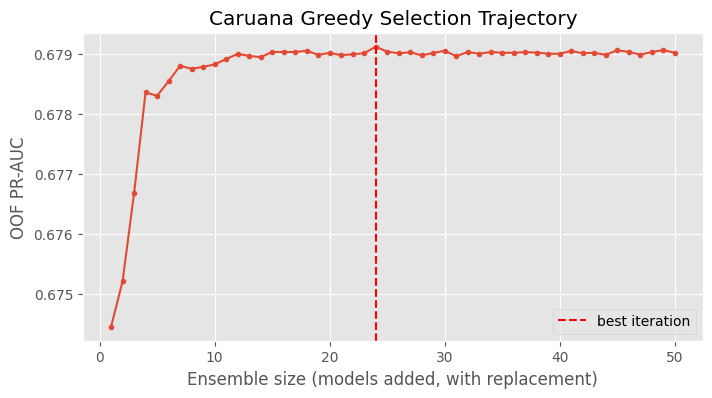


NESTED VALIDATION PR-AUC (25 outer folds)
               Mean     Std
Caruana      0.6787  0.0279
Equal        0.6777  0.0275
Best single  0.6742  0.0289

Caruana - Equal: mean +0.0010 | Caruana wins in 64% of folds

WEIGHT STABILITY ACROSS OUTER FOLDS
        Model  Mean weight    Std
          SVM       0.2915 0.0561
Random Forest       0.3875 0.0796
      XGBoost       0.0025 0.0122
     CatBoost       0.2120 0.1302
     LightGBM       0.1066 0.0995

Saved caruana_weights.csv: {'SVM': 0.333, 'Random Forest': 0.417, 'XGBoost': 0.0, 'CatBoost': 0.208, 'LightGBM': 0.042}


In [40]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

SEED = 42

if "oof_matrix" not in globals():
    _oof = pd.read_csv("oof_predictions.csv")
    model_order = [c for c in _oof.columns if c != "y_true"]
    oof_matrix = _oof[model_order].to_numpy()
    y_oof = _oof["y_true"].to_numpy()
y_oof = np.asarray(y_oof)

# ---- Caruana greedy ensemble selection (with replacement, PR-AUC) ----
def caruana_select(P, y, max_iter=50):
    n, m = P.shape
    counts = np.zeros(m, dtype=int)
    running = np.zeros(n)
    history = []
    for it in range(1, max_iter + 1):
        scores = np.array([average_precision_score(y, (running + P[:, j]) / it) for j in range(m)])
        j = int(np.argmax(scores))                 # ties -> first model
        counts[j] += 1
        running += P[:, j]
        history.append({"iter": it, "added": j, "score": scores[j], "counts": counts.copy()})
    best = int(np.argmax([h["score"] for h in history]))   # earliest best iteration
    weights = history[best]["counts"] / history[best]["counts"].sum()
    return weights, history, best

MAX_ITER = 50
t0 = time.time()
weights, history, best_idx = caruana_select(oof_matrix, y_oof, MAX_ITER)
caruana_time = time.time() - t0

print(f"Best iteration: {history[best_idx]['iter']} of {MAX_ITER} | selection time: {caruana_time:.2f}s")
print("\nSELECTION HISTORY (first 15 iterations)")
print(pd.DataFrame([{"Iteration": h["iter"], "Model added": model_order[h["added"]],
                     "Ensemble PR-AUC": round(h["score"], 4)} for h in history[:15]]).to_string(index=False))

final_counts = history[-1]["counts"]
summary = pd.DataFrame({"Model": model_order,
                        "Selections (all iterations)": final_counts,
                        "Selection frequency": final_counts / final_counts.sum(),
                        "Weight at best iteration": weights})
print("\nSELECTION FREQUENCY AND FINAL WEIGHTS")
print(summary.round(4).to_string(index=False))

# ---- In-sample comparison on OOF (optimistic) ----
def metrics(name, p):
    return {"Ensemble": name,
            "PR-AUC": average_precision_score(y_oof, p), "ROC-AUC": roc_auc_score(y_oof, p),
            "Brier": brier_score_loss(y_oof, p),
            "Log Loss": log_loss(y_oof, np.clip(p, 1e-15, 1 - 1e-15))}

single_best = int(np.argmax([average_precision_score(y_oof, oof_matrix[:, j]) for j in range(len(model_order))]))
print("\nIN-SAMPLE OOF COMPARISON (selection data, optimistic)")
print(pd.DataFrame([metrics(f"Best single ({model_order[single_best]})", oof_matrix[:, single_best]),
                    metrics("Equal weights", oof_matrix.mean(axis=1)),
                    metrics("Caruana", oof_matrix @ weights)]).round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot([h["iter"] for h in history], [h["score"] for h in history], marker="o", ms=3)
plt.axvline(history[best_idx]["iter"], color="red", ls="--", label="best iteration")
plt.xlabel("Ensemble size (models added, with replacement)"); plt.ylabel("OOF PR-AUC")
plt.title("Caruana Greedy Selection Trajectory"); plt.legend(); plt.show()

# ---- Nested validation: select on 4/5 of the OOF rows, score on the other 1/5 ----
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rows, fold_weights = [], []
for tr, te in rskf.split(oof_matrix, y_oof):
    w, _, _ = caruana_select(oof_matrix[tr], y_oof[tr], MAX_ITER)
    b = int(np.argmax([average_precision_score(y_oof[tr], oof_matrix[tr, j]) for j in range(oof_matrix.shape[1])]))
    rows.append({"Caruana": average_precision_score(y_oof[te], oof_matrix[te] @ w),
                 "Equal": average_precision_score(y_oof[te], oof_matrix[te].mean(axis=1)),
                 "Best single": average_precision_score(y_oof[te], oof_matrix[te, b])})
    fold_weights.append(w)
nested = pd.DataFrame(rows)
print("\nNESTED VALIDATION PR-AUC (25 outer folds)")
print(pd.DataFrame({"Mean": nested.mean(), "Std": nested.std()}).round(4).to_string())
diff = nested["Caruana"] - nested["Equal"]
print(f"\nCaruana - Equal: mean {diff.mean():+.4f} | Caruana wins in {(diff > 0).mean():.0%} of folds")
fw = np.array(fold_weights)
print("\nWEIGHT STABILITY ACROSS OUTER FOLDS")
print(pd.DataFrame({"Model": model_order, "Mean weight": fw.mean(0), "Std": fw.std(0)}).round(4).to_string(index=False))

# ---- Freeze for the final comparison ----
caruana_weights = {m: float(w) for m, w in zip(model_order, weights)}
pd.DataFrame({"Model": model_order, "Weight": weights}).to_csv("caruana_weights.csv", index=False)
print("\nSaved caruana_weights.csv:", {k: round(v, 3) for k, v in caruana_weights.items()})

In [41]:
import time, math
import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, precision_recall_curve)

SEED = 42

# ---------- Inputs ----------
if "oof_matrix" not in globals():
    _oof = pd.read_csv("oof_predictions.csv")
    model_order = [c for c in _oof.columns if c != "y_true"]
    oof_matrix = _oof[model_order].to_numpy()
    y_oof = _oof["y_true"].to_numpy()
y_oof = np.asarray(y_oof)

# ---------- Optimizers (same as the previous stages) ----------
def to_weights(x):
    x = np.clip(x, 0.0, 1.0); s = x.sum()
    return x / s if s > 1e-12 else np.full_like(x, 1.0 / len(x))

def levy_step(dim, rng, beta=1.5):
    sigma = (math.gamma(1 + beta) * math.sin(math.pi * beta / 2) /
             (math.gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))) ** (1 / beta)
    return rng.normal(0, sigma, dim) / np.abs(rng.normal(0, 1, dim)) ** (1 / beta)

def fpa_optimize(P, y, pop_size=20, n_iter=50, p_switch=0.8, gamma=0.1, seed=SEED):
    rng = np.random.default_rng(seed); dim = P.shape[1]
    fitness = lambda x: average_precision_score(y, P @ to_weights(x))
    pop = rng.random((pop_size, dim)); fit = np.array([fitness(x) for x in pop]); n_evals = pop_size
    b = int(np.argmax(fit)); g_best, g_fit = pop[b].copy(), fit[b]; history = [g_fit]
    for _ in range(n_iter):
        for i in range(pop_size):
            if rng.random() < p_switch:
                new = pop[i] + gamma * levy_step(dim, rng) * (g_best - pop[i])
            else:
                j, k = rng.choice(pop_size, 2, replace=False)
                new = pop[i] + rng.random() * (pop[j] - pop[k])
            new = np.clip(new, 0.0, 1.0); nf = fitness(new); n_evals += 1
            if nf > fit[i]:
                pop[i], fit[i] = new, nf
                if nf > g_fit: g_best, g_fit = new.copy(), nf
        history.append(g_fit)
    return to_weights(g_best), g_fit, history, n_evals

def caruana_select(P, y, max_iter=50):
    n, m = P.shape; counts = np.zeros(m, dtype=int); running = np.zeros(n); hist = []
    for it in range(1, max_iter + 1):
        scores = np.array([average_precision_score(y, (running + P[:, j]) / it) for j in range(m)])
        j = int(np.argmax(scores)); counts[j] += 1; running += P[:, j]
        hist.append((scores[j], counts.copy()))
    b = int(np.argmax([h[0] for h in hist]))
    return hist[b][1] / hist[b][1].sum()

# ---------- Metric helpers ----------
def ece_score(y, p, n_bins=10):
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1); e = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[int(np.argmax(f1))])

def prob_metrics(y, p):
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "Brier": brier_score_loss(y, p), "Log Loss": log_loss(y, np.clip(p, 1e-15, 1 - 1e-15)),
            "ECE": ece_score(y, p)}

def class_metrics(y, p, thr):
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {"Threshold": thr, "Accuracy": accuracy_score(y, yh),
            "Precision": precision_score(y, yh, zero_division=0), "Recall": recall_score(y, yh),
            "F1": f1_score(y, yh), "TN": tn, "FP": fp, "FN": fn, "TP": tp}

# ---------- Build all methods on the full OOF matrix ----------
t0 = time.time(); fpa_w, _, _, fpa_evals = fpa_optimize(oof_matrix, y_oof); fpa_time = time.time() - t0
t0 = time.time(); caruana_w = caruana_select(oof_matrix, y_oof); caruana_time = time.time() - t0
equal_w = np.full(len(model_order), 1 / len(model_order))

scores = {m: oof_matrix[:, j] for j, m in enumerate(model_order)}
scores["Equal weights"] = oof_matrix @ equal_w
scores["Caruana"] = oof_matrix @ caruana_w
scores["FPA"] = oof_matrix @ fpa_w

print("WEIGHTS")
print(pd.DataFrame({"Equal": equal_w, "Caruana": caruana_w, "FPA": fpa_w}, index=model_order).round(4).to_string())

t1 = pd.DataFrame([{"Method": n, **prob_metrics(y_oof, p)} for n, p in scores.items()])
print("\n1) PROBABILITY METRICS (threshold-free, in-sample OOF)")
print(t1.round(4).to_string(index=False))

t2 = pd.DataFrame([{"Method": n, **class_metrics(y_oof, p, 0.5)} for n, p in scores.items()])
print("\n2) CLASSIFICATION METRICS at threshold 0.5 (in-sample OOF)")
print(t2.round(4).to_string(index=False))

t3 = pd.DataFrame([{"Method": n, **class_metrics(y_oof, p, best_f1_threshold(y_oof, p))} for n, p in scores.items()])
print("\n3) CLASSIFICATION METRICS at the F1-optimal threshold (in-sample OOF, optimistic)")
print(t3.round(4).to_string(index=False))

# ---------- Nested validation (honest): weights AND threshold chosen on training folds only ----------
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rows = []
t0 = time.time()
for tr, te in rskf.split(oof_matrix, y_oof):
    w_f, _, _, _ = fpa_optimize(oof_matrix[tr], y_oof[tr]); w_c = caruana_select(oof_matrix[tr], y_oof[tr])
    fold = {m: oof_matrix[:, j] for j, m in enumerate(model_order)}
    fold["Equal weights"] = oof_matrix @ equal_w; fold["Caruana"] = oof_matrix @ w_c; fold["FPA"] = oof_matrix @ w_f
    for n, p in fold.items():
        thr = best_f1_threshold(y_oof[tr], p[tr])
        rows.append({"Method": n, **prob_metrics(y_oof[te], p[te]), **class_metrics(y_oof[te], p[te], thr)})
nest = pd.DataFrame(rows).drop(columns=["TN", "FP", "FN", "TP"])
cols = ["PR-AUC", "ROC-AUC", "Brier", "Log Loss", "ECE", "Accuracy", "Precision", "Recall", "F1"]
g = nest.groupby("Method", sort=False)[cols]
t4 = (g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str))
print(f"\n4) NESTED VALIDATION, mean ± std over 25 outer folds ({time.time()-t0:.0f}s)")
print("   (weights and F1 threshold chosen on training folds only)")
print(t4.to_string())

# ---------- Optimization cost ----------
t5 = pd.DataFrame([{"Method": "Equal weights", "Time (s)": 0.0, "Evaluations": 0},
                   {"Method": "Caruana", "Time (s)": caruana_time, "Evaluations": 50 * len(model_order)},
                   {"Method": "FPA", "Time (s)": fpa_time, "Evaluations": fpa_evals}])
print("\n5) OPTIMIZATION COST (full OOF matrix)")
print(t5.round(3).to_string(index=False))

WEIGHTS
               Equal  Caruana     FPA
SVM              0.2   0.3333  0.3374
Random Forest    0.2   0.4167  0.4117
XGBoost          0.2   0.0000  0.0000
CatBoost         0.2   0.2083  0.2077
LightGBM         0.2   0.0417  0.0432

1) PROBABILITY METRICS (threshold-free, in-sample OOF)
       Method  PR-AUC  ROC-AUC  Brier  Log Loss    ECE
          SVM  0.6585   0.8432 0.1379    0.4247 0.0378
Random Forest  0.6716   0.8450 0.1460    0.4423 0.0850
      XGBoost  0.6407   0.8308 0.1538    0.4673 0.0827
     CatBoost  0.6744   0.8508 0.1326    0.4091 0.0107
     LightGBM  0.6745   0.8506 0.1391    0.4254 0.0671
Equal weights  0.6761   0.8492 0.1364    0.4180 0.0474
      Caruana  0.6791   0.8501 0.1352    0.4155 0.0425
          FPA  0.6791   0.8501 0.1352    0.4155 0.0422

2) CLASSIFICATION METRICS at threshold 0.5 (in-sample OOF)
       Method  Threshold  Accuracy  Precision  Recall     F1   TN  FP  FN  TP
          SVM        0.5    0.8067     0.6611  0.5577 0.6050 2969 342 529 6

In [42]:
import time, math
import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, precision_recall_curve)

SEED = 42
ALPHAS = [0.05, 0.10, 0.15, 0.20]

# ---------- Inputs ----------
if "oof_matrix" not in globals():
    _oof = pd.read_csv("oof_predictions.csv")
    model_order = [c for c in _oof.columns if c != "y_true"]
    oof_matrix = _oof[model_order].to_numpy()
    y_oof = _oof["y_true"].to_numpy()
y_oof = np.asarray(y_oof)
m_models = len(model_order)
xgb_idx = model_order.index("XGBoost")
others = [i for i in range(m_models) if i != xgb_idx]

# ---------- Weight mapping ----------
def to_weights(x):
    x = np.clip(x, 0.0, 1.0); s = x.sum()
    return x / s if s > 1e-12 else np.full_like(x, 1.0 / len(x))

def make_weight_fn(alpha):
    """alpha = 0: all 5 weights free. alpha > 0: XGBoost fixed at alpha, the other 4 share 1 - alpha.
    Applied to EVERY candidate before fitness is computed."""
    if alpha == 0:
        return to_weights, m_models
    def fn(x):
        w = np.zeros(m_models)
        w[xgb_idx] = alpha
        w[others] = (1 - alpha) * to_weights(x)
        return w
    return fn, len(others)

# ---------- FPA ----------
def levy_step(dim, rng, beta=1.5):
    sigma = (math.gamma(1 + beta) * math.sin(math.pi * beta / 2) /
             (math.gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))) ** (1 / beta)
    return rng.normal(0, sigma, dim) / np.abs(rng.normal(0, 1, dim)) ** (1 / beta)

def fpa_optimize(P, y, alpha=0.0, pop_size=20, n_iter=50, p_switch=0.8, gamma=0.1, seed=SEED):
    wfn, dim = make_weight_fn(alpha)
    rng = np.random.default_rng(seed)
    fitness = lambda x: average_precision_score(y, P @ wfn(x))
    pop = rng.random((pop_size, dim)); fit = np.array([fitness(x) for x in pop]); n_evals = pop_size
    b = int(np.argmax(fit)); g_best, g_fit = pop[b].copy(), fit[b]
    for _ in range(n_iter):
        for i in range(pop_size):
            if rng.random() < p_switch:
                new = pop[i] + gamma * levy_step(dim, rng) * (g_best - pop[i])
            else:
                j, k = rng.choice(pop_size, 2, replace=False)
                new = pop[i] + rng.random() * (pop[j] - pop[k])
            new = np.clip(new, 0.0, 1.0); nf = fitness(new); n_evals += 1
            if nf > fit[i]:
                pop[i], fit[i] = new, nf
                if nf > g_fit: g_best, g_fit = new.copy(), nf
    return wfn(g_best), g_fit, n_evals

# ---------- Caruana ----------
def caruana_select(P, y, max_iter=50):
    n, m = P.shape; counts = np.zeros(m, dtype=int); running = np.zeros(n); hist = []
    for it in range(1, max_iter + 1):
        scores = np.array([average_precision_score(y, (running + P[:, j]) / it) for j in range(m)])
        j = int(np.argmax(scores)); counts[j] += 1; running += P[:, j]
        hist.append((scores[j], counts.copy()))
    b = int(np.argmax([h[0] for h in hist]))
    return hist[b][1] / hist[b][1].sum()

def caruana_forced(P, y, alpha, max_iter=50):
    """XGBoost fixed at alpha. Each greedy step scores the FULL weighted ensemble
    (including the XGBoost share), choosing among the other four models."""
    counts = np.zeros(m_models, dtype=int); hist = []
    def weights_for(c, t):
        w = np.zeros(m_models); w[xgb_idx] = alpha; w[others] = (1 - alpha) * c[others] / t
        return w
    for it in range(1, max_iter + 1):
        best_j, best_s = None, -1
        for j in others:
            c = counts.copy(); c[j] += 1
            s = average_precision_score(y, P @ weights_for(c, it))
            if s > best_s: best_j, best_s = j, s
        counts[best_j] += 1
        hist.append((best_s, weights_for(counts, it)))
    return hist[int(np.argmax([h[0] for h in hist]))][1]

# ---------- Metrics ----------
def ece_score(y, p, n_bins=10):
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1); e = 0.0
    for b in range(n_bins):
        mk = bins == b
        if mk.any(): e += mk.mean() * abs(y[mk].mean() - p[mk].mean())
    return e

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[int(np.argmax(f1))])

def prob_metrics(y, p):
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "Brier": brier_score_loss(y, p), "Log Loss": log_loss(y, np.clip(p, 1e-15, 1 - 1e-15)),
            "ECE": ece_score(y, p)}

def class_metrics(y, p, thr):
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {"Threshold": thr, "Accuracy": accuracy_score(y, yh), "Precision": precision_score(y, yh, zero_division=0),
            "Recall": recall_score(y, yh), "F1": f1_score(y, yh), "TN": tn, "FP": fp, "FN": fn, "TP": tp}

# ---------- Build every method's weights ----------
def build_all_weights(P, y):
    W, cost = {}, {}
    W["Equal weights (XGB 20%)"] = np.full(m_models, 1 / m_models); cost["Equal weights (XGB 20%)"] = (0.0, 0)
    t = time.time(); W["Caruana (XGB free)"] = caruana_select(P, y); cost["Caruana (XGB free)"] = (time.time() - t, 50 * m_models)
    t = time.time(); w, _, ev = fpa_optimize(P, y, alpha=0.0); W["FPA (XGB free)"] = w; cost["FPA (XGB free)"] = (time.time() - t, ev)
    for a in ALPHAS:
        t = time.time(); W[f"Caruana XGB={a:.0%}"] = caruana_forced(P, y, a); cost[f"Caruana XGB={a:.0%}"] = (time.time() - t, 50 * len(others))
        t = time.time(); w, _, ev = fpa_optimize(P, y, alpha=a); W[f"FPA XGB={a:.0%}"] = w; cost[f"FPA XGB={a:.0%}"] = (time.time() - t, ev)
    return W, cost

W_full, cost_full = build_all_weights(oof_matrix, y_oof)
scores = {n: oof_matrix @ w for n, w in W_full.items()}

print("WEIGHTS (full OOF)")
print(pd.DataFrame(W_full, index=model_order).T.round(4).to_string())

print("\n1) PROBABILITY METRICS (in-sample OOF; optimistic)")
print(pd.DataFrame([{"Method": n, **prob_metrics(y_oof, p)} for n, p in scores.items()]).round(4).to_string(index=False))

print("\n2) CLASSIFICATION METRICS at threshold 0.5 (in-sample OOF)")
print(pd.DataFrame([{"Method": n, **class_metrics(y_oof, p, 0.5)} for n, p in scores.items()]).round(4).to_string(index=False))

# ---------- Nested validation ----------
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rows = []
t0 = time.time()
for tr, te in rskf.split(oof_matrix, y_oof):
    Wf, _ = build_all_weights(oof_matrix[tr], y_oof[tr])
    for n, w in Wf.items():
        p = oof_matrix @ w
        thr = best_f1_threshold(y_oof[tr], p[tr])
        rows.append({"Method": n, **prob_metrics(y_oof[te], p[te]), **class_metrics(y_oof[te], p[te], thr)})
nest = pd.DataFrame(rows)
cols = ["PR-AUC", "ROC-AUC", "Brier", "Log Loss", "ECE", "Accuracy", "Precision", "Recall", "F1"]
g = nest.drop(columns=["TN", "FP", "FN", "TP"]).groupby("Method", sort=False)[cols]
print(f"\n3) NESTED VALIDATION, mean ± std over 25 outer folds ({time.time()-t0:.0f}s)")
print("   (weights and F1 threshold chosen on training folds only)")
print((g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)).to_string())

# Paired comparison: does forcing XGBoost beat leaving it free?
print("\n4) PAIRED COMPARISON vs the unconstrained method (same 25 folds)")
piv = {c: nest.pivot_table(index=nest.groupby("Method").cumcount(), columns="Method", values=c) for c in ["PR-AUC", "Brier"]}
cmp_rows = []
for fam, base in [("Caruana", "Caruana (XGB free)"), ("FPA", "FPA (XGB free)")]:
    for a in ALPHAS:
        name = f"{fam} XGB={a:.0%}"
        dp = piv["PR-AUC"][name] - piv["PR-AUC"][base]; db = piv["Brier"][base] - piv["Brier"][name]
        cmp_rows.append({"Method": name, "dPR-AUC vs free": dp.mean(), "PR-AUC win%": (dp > 0).mean() * 100,
                         "dBrier gain vs free": db.mean(), "Brier win%": (db > 0).mean() * 100})
print(pd.DataFrame(cmp_rows).round(4).to_string(index=False))

print("\n5) OPTIMIZATION COST (full OOF)")
print(pd.DataFrame([{"Method": n, "Time (s)": round(t, 3), "Evaluations": e} for n, (t, e) in cost_full.items()]).to_string(index=False))

WEIGHTS (full OOF)
                            SVM  Random Forest  XGBoost  CatBoost  LightGBM
Equal weights (XGB 20%)  0.2000         0.2000     0.20    0.2000    0.2000
Caruana (XGB free)       0.3333         0.4167     0.00    0.2083    0.0417
FPA (XGB free)           0.3374         0.4117     0.00    0.2077    0.0432
Caruana XGB=5%           0.3167         0.3800     0.05    0.2533    0.0000
FPA XGB=5%               0.3173         0.3789     0.05    0.2504    0.0035
Caruana XGB=10%          0.3522         0.3130     0.10    0.1174    0.1174
FPA XGB=10%              0.3439         0.3126     0.10    0.1575    0.0861
Caruana XGB=15%          0.3643         0.3339     0.15    0.0911    0.0607
FPA XGB=15%              0.3371         0.3483     0.15    0.1046    0.0599
Caruana XGB=20%          0.3200         0.1600     0.20    0.1920    0.1280
FPA XGB=20%              0.3202         0.1543     0.20    0.2007    0.1248

1) PROBABILITY METRICS (in-sample OOF; optimistic)
                 

In [43]:
# =====================================================================
# CELL 0 - SETUP + PREFLIGHT  (run this first, every time the kernel restarts)
# =====================================================================
import os, time, math, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

SEED = 42
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

# Only used if X_dev / y_dev / prep are NOT already defined by your earlier cells.
# Leave as None to auto-detect; set them only if auto-detection picks the wrong file/column.
DATA_PATH = None   # e.g. "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
TARGET = None      # e.g. "Churn"
ID_COLS = []       # extra columns to drop; unique-per-row columns are dropped automatically

_TARGET_HINTS = ["churn", "exited", "attrition", "left", "target", "label"]
_OWN_OUTPUTS = {"model_calibration_results.csv", "calibrated_oof_predictions.csv", "oof_predictions.csv"}


def _resolve_dataset():
    """Finds DATA_PATH and TARGET automatically. Returns True if both are usable."""
    global DATA_PATH, TARGET

    if DATA_PATH is not None and os.path.exists(DATA_PATH) and TARGET is not None:
        return True

    paths = [DATA_PATH] if DATA_PATH and os.path.exists(DATA_PATH) else []
    if not paths:
        for root in ["/kaggle/input", "/kaggle/working", "."]:
            if os.path.isdir(root):
                for dp, _, fs in os.walk(root):
                    paths += [os.path.join(dp, f) for f in fs
                              if f.lower().endswith(".csv") and f not in _OWN_OUTPUTS]
    paths = sorted(set(paths))
    print("CSV files found:", paths if paths else "none")

    for p in paths:
        try:
            cols = list(pd.read_csv(p, nrows=5).columns)
        except Exception:
            continue
        if TARGET is not None:
            hit = TARGET if TARGET in cols else None
        else:
            hit = next((c for h in _TARGET_HINTS for c in cols if h in c.lower()), None)
        if hit:
            DATA_PATH, TARGET = p, hit
            print(f"Using dataset: {DATA_PATH} | target column: {TARGET}")
            return True
    return False


EXPECTED_MODELS = ["SVM", "RandomForest", "XGBoost", "CatBoost", "LightGBM"]


def _make_models():
    """The ensemble: SVM, Random Forest, XGBoost, CatBoost, LightGBM. Nothing else."""
    from sklearn.svm import SVC
    from sklearn.ensemble import RandomForestClassifier
    try:
        from xgboost import XGBClassifier
        from catboost import CatBoostClassifier
        from lightgbm import LGBMClassifier
    except ImportError as e:
        raise ImportError(f"{e}. Install with: !pip install xgboost catboost lightgbm") from e

    models = {
        "SVM": SVC(kernel="rbf", C=1.0, gamma="scale", probability=True,
                   cache_size=1000, random_state=SEED),
        "RandomForest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                 eval_metric="logloss", random_state=SEED, n_jobs=-1),
        "CatBoost": CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6,
                                       random_seed=SEED, verbose=0, thread_count=-1,
                                       allow_writing_files=False),
        "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                   random_state=SEED, n_jobs=-1, verbose=-1),
    }
    assert list(models) == EXPECTED_MODELS, f"Unexpected models: {list(models)}"
    return models


def _build_fallback():
    """Rebuilds X_dev, y_dev, prep from the CSV so the notebook can run top to bottom."""
    from sklearn.model_selection import train_test_split
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline

    df = pd.read_csv(DATA_PATH)
    df = df.dropna(subset=[TARGET])
    y = df[TARGET]
    if y.dtype == object:
        y = y.astype(str).str.strip().str.lower().map(
            {"yes": 1, "no": 0, "1": 1, "0": 0, "true": 1, "false": 0,
             "churn": 1, "churned": 1, "left": 1, "stayed": 0, "retained": 0, "exited": 1})
        if y.isna().any():
            raise ValueError(f"Could not map target column '{TARGET}' to 0/1. "
                             f"Values: {df[TARGET].unique()[:10]}")
    y = y.astype(int)
    X = df.drop(columns=[TARGET])
    # drop explicit ID columns and any column that is unique per row (customer IDs, row numbers)
    drop_ids = [c for c in X.columns if c in ID_COLS or X[c].nunique() == len(X)]
    if drop_ids:
        print("Dropping ID-like columns:", drop_ids)
        X = X.drop(columns=drop_ids)

    # Fix numeric columns that were read as text (e.g. Telco "TotalCharges")
    for c in X.columns:
        if X[c].dtype == object:
            conv = pd.to_numeric(X[c], errors="coerce")
            if conv.notna().mean() > 0.95:
                X[c] = conv

    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=SEED
    )

    num_cols = X_dev.select_dtypes(include="number").columns.tolist()
    cat_cols = [c for c in X_dev.columns if c not in num_cols]
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:                       # older scikit-learn
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", ohe)]), cat_cols),
    ])
    return X_dev, y_dev, prep


def preflight():
    g = globals()

    # Always (re)define the models, so stale variables from earlier runs can never leak in.
    g["raw_models"] = _make_models()

    missing = [n for n in ["X_dev", "y_dev", "prep"] if n not in g]
    if missing:
        print(f"Missing {missing} -> trying to rebuild from a CSV...")
        if _resolve_dataset():
            g["X_dev"], g["y_dev"], g["prep"] = _build_fallback()
        else:
            raise RuntimeError(
                f"Missing variables: {missing}, and no churn CSV with a recognisable target "
                "column was found.\n"
                "Fix: (1) click '+ Add Input' on Kaggle to attach your churn dataset, or "
                "(2) set DATA_PATH and TARGET at the top of Cell 0 using the CSV list printed above, or "
                "(3) run the earlier cells that define X_dev, y_dev and prep."
            )

    # Basic sanity checks
    if len(g["X_dev"]) != len(g["y_dev"]):
        raise ValueError(f"X_dev ({len(g['X_dev'])}) and y_dev ({len(g['y_dev'])}) lengths differ.")
    if list(g["raw_models"]) != EXPECTED_MODELS:
        raise ValueError(f"raw_models must be {EXPECTED_MODELS}, got {list(g['raw_models'])}")
    if not set(np.unique(np.asarray(g["y_dev"]))) <= {0, 1}:
        raise ValueError("y_dev must be binary 0/1.")
    print("Preflight OK:", g["X_dev"].shape, "| models:", list(g["raw_models"].keys()))


preflight()


# =====================================================================
# CELL 1 - CALIBRATION FRAMEWORK
# =====================================================================
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
                             accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, precision_recall_curve)

try:
    from IPython.display import display
except ImportError:
    display = print

y_arr = np.asarray(y_dev).astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print("Customer Churn Prediction Framework Initialized")
print("Development dataset:", X_dev.shape)
print("Models:", list(raw_models.keys()))

models_for_framework = {}
for name, model in raw_models.items():
    if isinstance(model, Pipeline):
        models_for_framework[name] = clone(model)
    else:
        models_for_framework[name] = Pipeline([("preprocessor", clone(prep)), ("model", clone(model))])
print(f"{len(models_for_framework)} model pipelines prepared.")


def make_calibrated(model, method):
    # sklearn >= 1.2 uses `estimator`; older versions use `base_estimator`
    try:
        return CalibratedClassifierCV(estimator=clone(model), method=method, cv=5, n_jobs=1)
    except TypeError:
        return CalibratedClassifierCV(base_estimator=clone(model), method=method, cv=5)


def calculate_ece(y_true, probabilities, n_bins=10):
    y_true = np.asarray(y_true); p = np.asarray(probabilities)
    edges = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for i in range(n_bins):
        mask = (p >= edges[i]) & ((p <= edges[i + 1]) if i == n_bins - 1 else (p < edges[i + 1]))
        if mask.any():
            ece += mask.mean() * abs(y_true[mask].mean() - p[mask].mean())
    return ece


framework_results, framework_oof = [], {}
calibration_methods = ["raw", "sigmoid", "isotonic"]
total = len(models_for_framework) * len(calibration_methods)
counter = 0

for model_name, model in models_for_framework.items():
    print("\n" + "=" * 60 + f"\nMODEL: {model_name}\n" + "=" * 60)
    for method in calibration_methods:
        counter += 1
        print(f"\n[{counter}/{total}] {model_name} - {method}")
        start = time.time()

        estimator = clone(model) if method == "raw" else make_calibrated(model, method)

        probabilities = cross_val_predict(
            estimator, X_dev, y_arr, cv=cv, method="predict_proba", n_jobs=1
        )[:, 1]
        probabilities = np.clip(probabilities, 0.0, 1.0)          # safety clip
        framework_oof[f"{model_name}_{method}"] = probabilities

        pr_auc = average_precision_score(y_arr, probabilities)
        roc_auc = roc_auc_score(y_arr, probabilities)
        brier = brier_score_loss(y_arr, probabilities)
        logloss = log_loss(y_arr, np.clip(probabilities, 1e-15, 1 - 1e-15))
        ece = calculate_ece(y_arr, probabilities)

        precision, recall, thresholds = precision_recall_curve(y_arr, probabilities)
        f1_values = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
        best_threshold = thresholds[int(np.argmax(f1_values))]
        preds = (probabilities >= best_threshold).astype(int)

        framework_results.append({
            "Model": model_name, "Calibration": method,
            "PR_AUC": pr_auc, "ROC_AUC": roc_auc, "Brier": brier, "LogLoss": logloss, "ECE": ece,
            "Accuracy": accuracy_score(y_arr, preds),
            "Precision": precision_score(y_arr, preds, zero_division=0),
            "Recall": recall_score(y_arr, preds, zero_division=0),
            "F1": f1_score(y_arr, preds, zero_division=0),
            "MCC": matthews_corrcoef(y_arr, preds),
            "Threshold": best_threshold, "Training_Time": time.time() - start,
        })
        print(f"PR-AUC: {pr_auc:.4f} | ROC-AUC: {roc_auc:.4f} | Brier: {brier:.4f} | "
              f"LogLoss: {logloss:.4f} | ECE: {ece:.4f}")

print("\nAll model calibration procedures completed.")

framework_results_df = (pd.DataFrame(framework_results)
                        .sort_values("PR_AUC", ascending=False).reset_index(drop=True))
display(framework_results_df.round(4))

display(framework_results_df.pivot(index="Model", columns="Calibration",
                                   values=["PR_AUC", "ROC_AUC", "Brier", "LogLoss", "ECE"]).round(4))

framework_results_df.to_csv(os.path.join(OUT_DIR, "model_calibration_results.csv"), index=False)
framework_oof_df = pd.DataFrame(framework_oof)
framework_oof_df["Actual"] = y_arr
framework_oof_df.to_csv(os.path.join(OUT_DIR, "calibrated_oof_predictions.csv"), index=False)

# ---- Bridge to Cell 2: one OOF column per model (best-Brier calibration), plus y_true ----
best_cal = (framework_results_df.sort_values("Brier").groupby("Model", sort=False).head(1)
            .set_index("Model")["Calibration"])
model_order = list(raw_models.keys())
oof_df = pd.DataFrame({m: framework_oof[f"{m}_{best_cal[m]}"] for m in model_order})
oof_df["y_true"] = y_arr
oof_df.to_csv(os.path.join(OUT_DIR, "oof_predictions.csv"), index=False)

oof_matrix = oof_df[model_order].to_numpy()
y_oof = y_arr
print("\nCalibration chosen per model (lowest Brier):")
print(best_cal.to_string())
print("Saved: model_calibration_results.csv, calibrated_oof_predictions.csv, oof_predictions.csv")


# =====================================================================
# CELL 2 - ENSEMBLE WEIGHTING (Caruana / FPA with XGBoost forced share)
# =====================================================================
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import confusion_matrix

ALPHAS = [0.05, 0.10, 0.15, 0.20]

# ---------- Inputs (guarded) ----------
if "oof_matrix" not in globals() or "model_order" not in globals() or "y_oof" not in globals():
    _path = os.path.join(OUT_DIR, "oof_predictions.csv")
    if not os.path.exists(_path):
        raise FileNotFoundError(f"{_path} not found. Run Cell 1 first.")
    _oof = pd.read_csv(_path)
    model_order = [c for c in _oof.columns if c != "y_true"]
    oof_matrix = _oof[model_order].to_numpy()
    y_oof = _oof["y_true"].to_numpy()
y_oof = np.asarray(y_oof).astype(int)
oof_matrix = np.clip(np.asarray(oof_matrix, dtype=float), 0.0, 1.0)
m_models = len(model_order)

_xgb = [i for i, n in enumerate(model_order) if "xgb" in n.lower()]
if not _xgb:
    raise ValueError(f"No XGBoost model found in {model_order}")
xgb_idx = _xgb[0]
others = [i for i in range(m_models) if i != xgb_idx]


def blend(P, w):
    """Weighted blend of model probabilities, always kept inside [0, 1].
    Floating-point rounding can push a blend of exact 1.0 values to 1.0000000000000002,
    which brier_score_loss rejects, so every blend goes through this function."""
    return np.clip(P @ np.asarray(w, dtype=float), 0.0, 1.0)


def to_weights(x):
    x = np.clip(x, 0.0, 1.0); s = x.sum()
    return x / s if s > 1e-12 else np.full_like(x, 1.0 / len(x))


def make_weight_fn(alpha):
    if alpha == 0:
        return to_weights, m_models
    def fn(x):
        w = np.zeros(m_models)
        w[xgb_idx] = alpha
        w[others] = (1 - alpha) * to_weights(x)
        return w
    return fn, len(others)


def levy_step(dim, rng, beta=1.5):
    sigma = (math.gamma(1 + beta) * math.sin(math.pi * beta / 2) /
             (math.gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))) ** (1 / beta)
    return rng.normal(0, sigma, dim) / np.abs(rng.normal(0, 1, dim)) ** (1 / beta)


def fpa_optimize(P, y, alpha=0.0, pop_size=20, n_iter=50, p_switch=0.8, gamma=0.1, seed=SEED):
    wfn, dim = make_weight_fn(alpha)
    rng = np.random.default_rng(seed)
    fitness = lambda x: average_precision_score(y, blend(P, wfn(x)))
    pop = rng.random((pop_size, dim)); fit = np.array([fitness(x) for x in pop]); n_evals = pop_size
    b = int(np.argmax(fit)); g_best, g_fit = pop[b].copy(), fit[b]
    for _ in range(n_iter):
        for i in range(pop_size):
            if rng.random() < p_switch:
                new = pop[i] + gamma * levy_step(dim, rng) * (g_best - pop[i])
            else:
                j, k = rng.choice(pop_size, 2, replace=False)
                new = pop[i] + rng.random() * (pop[j] - pop[k])
            new = np.clip(new, 0.0, 1.0); nf = fitness(new); n_evals += 1
            if nf > fit[i]:
                pop[i], fit[i] = new, nf
                if nf > g_fit: g_best, g_fit = new.copy(), nf
    return wfn(g_best), g_fit, n_evals


def caruana_select(P, y, max_iter=50):
    n, m = P.shape; counts = np.zeros(m, dtype=int); running = np.zeros(n); hist = []
    for it in range(1, max_iter + 1):
        scores_ = np.array([average_precision_score(y, np.clip((running + P[:, j]) / it, 0.0, 1.0))
                            for j in range(m)])
        j = int(np.argmax(scores_)); counts[j] += 1; running += P[:, j]
        hist.append((scores_[j], counts.copy()))
    b = int(np.argmax([h[0] for h in hist]))
    return hist[b][1] / hist[b][1].sum()


def caruana_forced(P, y, alpha, max_iter=50):
    counts = np.zeros(m_models, dtype=int); hist = []
    def weights_for(c, t):
        w = np.zeros(m_models); w[xgb_idx] = alpha; w[others] = (1 - alpha) * c[others] / t
        return w
    for it in range(1, max_iter + 1):
        best_j, best_s = None, -1
        for j in others:
            c = counts.copy(); c[j] += 1
            s = average_precision_score(y, blend(P, weights_for(c, it)))
            if s > best_s: best_j, best_s = j, s
        counts[best_j] += 1
        hist.append((best_s, weights_for(counts, it)))
    return hist[int(np.argmax([h[0] for h in hist]))][1]


def ece_score(y, p, n_bins=10):
    y = np.asarray(y); p = np.asarray(p)
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1); e = 0.0
    for b in range(n_bins):
        mk = bins == b
        if mk.any(): e += mk.mean() * abs(y[mk].mean() - p[mk].mean())
    return e


def best_f1_threshold(y, p):
    p = np.clip(np.asarray(p, dtype=float), 0.0, 1.0)
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[int(np.argmax(f1))])


def prob_metrics(y, p):
    p = np.clip(np.asarray(p, dtype=float), 0.0, 1.0)
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "Brier": brier_score_loss(y, p), "Log Loss": log_loss(y, np.clip(p, 1e-15, 1 - 1e-15)),
            "ECE": ece_score(y, p)}


def class_metrics(y, p, thr):
    p = np.clip(np.asarray(p, dtype=float), 0.0, 1.0)
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {"Threshold": thr, "Accuracy": accuracy_score(y, yh),
            "Precision": precision_score(y, yh, zero_division=0),
            "Recall": recall_score(y, yh, zero_division=0), "F1": f1_score(y, yh, zero_division=0),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}


EQ = "Equal weights"
def build_all_weights(P, y):
    W, cost = {}, {}
    W[EQ] = np.full(m_models, 1 / m_models); cost[EQ] = (0.0, 0)
    t = time.time(); W["Caruana (XGB free)"] = caruana_select(P, y)
    cost["Caruana (XGB free)"] = (time.time() - t, 50 * m_models)
    t = time.time(); w, _, ev = fpa_optimize(P, y, alpha=0.0)
    W["FPA (XGB free)"] = w; cost["FPA (XGB free)"] = (time.time() - t, ev)
    for a in ALPHAS:
        t = time.time(); W[f"Caruana XGB={a:.0%}"] = caruana_forced(P, y, a)
        cost[f"Caruana XGB={a:.0%}"] = (time.time() - t, 50 * len(others))
        t = time.time(); w, _, ev = fpa_optimize(P, y, alpha=a)
        W[f"FPA XGB={a:.0%}"] = w; cost[f"FPA XGB={a:.0%}"] = (time.time() - t, ev)
    return W, cost


W_full, cost_full = build_all_weights(oof_matrix, y_oof)
scores = {n: blend(oof_matrix, w) for n, w in W_full.items()}

print("WEIGHTS (full OOF)")
print(pd.DataFrame(W_full, index=model_order).T.round(4).to_string())

print("\n1) PROBABILITY METRICS (in-sample OOF; optimistic)")
print(pd.DataFrame([{"Method": n, **prob_metrics(y_oof, p)} for n, p in scores.items()]).round(4).to_string(index=False))

print("\n2) CLASSIFICATION METRICS at threshold 0.5 (in-sample OOF)")
print(pd.DataFrame([{"Method": n, **class_metrics(y_oof, p, 0.5)} for n, p in scores.items()]).round(4).to_string(index=False))

# ---------- Nested validation ----------
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rows = []; t0 = time.time()
for tr, te in rskf.split(oof_matrix, y_oof):
    Wf, _ = build_all_weights(oof_matrix[tr], y_oof[tr])
    for n, w in Wf.items():
        p = blend(oof_matrix, w)
        thr = best_f1_threshold(y_oof[tr], p[tr])
        rows.append({"Method": n, **prob_metrics(y_oof[te], p[te]), **class_metrics(y_oof[te], p[te], thr)})
nest = pd.DataFrame(rows)
cols = ["PR-AUC", "ROC-AUC", "Brier", "Log Loss", "ECE", "Accuracy", "Precision", "Recall", "F1"]
g = nest.drop(columns=["TN", "FP", "FN", "TP"]).groupby("Method", sort=False)[cols]
print(f"\n3) NESTED VALIDATION, mean ± std over 25 outer folds ({time.time()-t0:.0f}s)")
print("   (weights and F1 threshold chosen on training folds only)")
print((g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)).to_string())

print("\n4) PAIRED COMPARISON vs the unconstrained method (same 25 folds)")
piv = {c: nest.pivot_table(index=nest.groupby("Method").cumcount(), columns="Method", values=c)
       for c in ["PR-AUC", "Brier"]}
cmp_rows = []
for fam, base in [("Caruana", "Caruana (XGB free)"), ("FPA", "FPA (XGB free)")]:
    for a in ALPHAS:
        name = f"{fam} XGB={a:.0%}"
        dp = piv["PR-AUC"][name] - piv["PR-AUC"][base]
        db = piv["Brier"][base] - piv["Brier"][name]
        cmp_rows.append({"Method": name, "dPR-AUC vs free": dp.mean(), "PR-AUC win%": (dp > 0).mean() * 100,
                         "dBrier gain vs free": db.mean(), "Brier win%": (db > 0).mean() * 100})
print(pd.DataFrame(cmp_rows).round(4).to_string(index=False))

print("\n5) OPTIMIZATION COST (full OOF)")
print(pd.DataFrame([{"Method": n, "Time (s)": round(t, 3), "Evaluations": e}
                    for n, (t, e) in cost_full.items()]).to_string(index=False))

Missing ['prep'] -> trying to rebuild from a CSV...
CSV files found: ['./caruana_weights.csv', '/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv', '/kaggle/working/caruana_weights.csv']
Using dataset: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv | target column: Churn
Dropping ID-like columns: ['customerID']
Preflight OK: (5634, 19) | models: ['SVM', 'RandomForest', 'XGBoost', 'CatBoost', 'LightGBM']
Customer Churn Prediction Framework Initialized
Development dataset: (5634, 19)
Models: ['SVM', 'RandomForest', 'XGBoost', 'CatBoost', 'LightGBM']
5 model pipelines prepared.

MODEL: SVM

[1/15] SVM - raw
PR-AUC: 0.6334 | ROC-AUC: 0.7986 | Brier: 0.1443 | LogLoss: 0.4554 | ECE: 0.0359

[2/15] SVM - sigmoid
PR-AUC: 0.6383 | ROC-AUC: 0.8050 | Brier: 0.1437 | LogLoss: 0.4530 | ECE: 0.0384

[3/15] SVM - isotonic
PR-AUC: 0.6388 | ROC-AUC: 0.8125 | Brier: 0.1405 | LogLoss: 0.4476 | ECE: 0.0192

MODEL: RandomF

,Model,Calibration,PR_AUC,ROC_AUC,Brier,LogLoss,ECE,Accuracy,Precision,Recall,F1,MCC,Threshold,Training_Time
0,XGBoost,sigmoid,0.6627,0.8460,0.1358,0.4236,0.0339,0.7835,0.5714,0.7358,0.6433,0.4994,0.2739,8.3082
1,XGBoost,isotonic,0.6614,0.8454,0.1347,0.4214,0.0131,0.7758,0.5573,0.7552,0.6413,0.4954,0.3126,5.8991
2,CatBoost,sigmoid,0.6590,0.8450,0.1369,0.4264,0.0381,0.7705,0.5486,0.7632,0.6383,0.4907,0.2427,23.1007
3,XGBoost,raw,0.6583,0.8444,0.1355,0.4185,0.0185,0.7733,0.5538,0.7505,0.6373,0.4896,0.3116,1.2018
4,CatBoost,isotonic,0.6560,0.8441,0.1357,0.4229,0.0127,0.7765,0.5595,0.7425,0.6381,0.4911,0.3229,22.0425
5,CatBoost,raw,0.6536,0.8429,0.1365,0.4205,0.0191,0.7721,0.5518,0.7512,0.6363,0.4879,0.3065,4.7630
6,LightGBM,sigmoid,0.6459,0.8364,0.1406,0.4383,0.0408,0.7721,0.5544,0.7197,0.6263,0.4745,0.2664,11.5191
7,LightGBM,isotonic,0.6407,0.8355,0.1391,0.4273,0.0137,0.7595,0.5328,0.7605,0.6266,0.4730,0.3049,9.4700
8,SVM,isotonic,0.6388,0.8125,0.1405,0.4476,0.0192,0.7836,0.5783,0.6816,0.6257,0.4782,0.3289,80.7889
9,SVM,sigmoid,0.6383,0.8050,0.1437,0.4530,0.0384,0.7748,0.5600,0.7050,0.6242,0.4727,0.2070,81.6528


PR_AUC                  ROC_AUC                    Brier  \
Calibration  isotonic     raw sigmoid isotonic     raw sigmoid isotonic   
Model                                                                     
CatBoost       0.6560  0.6536  0.6590   0.8441  0.8429  0.8450   0.1357   
LightGBM       0.6407  0.6352  0.6459   0.8355  0.8330  0.8364   0.1391   
RandomForest   0.6182  0.6121  0.6203   0.8258  0.8203  0.8274   0.1427   
SVM            0.6388  0.6334  0.6383   0.8125  0.7986  0.8050   0.1405   
XGBoost        0.6614  0.6583  0.6627   0.8454  0.8444  0.8460   0.1347   

                              LogLoss                      ECE                  
Calibration      raw sigmoid isotonic     raw sigmoid isotonic     raw sigmoid  
Model                                                                           
CatBoost      0.1365  0.1369   0.4229  0.4205  0.4264   0.0127  0.0191  0.0381  
LightGBM      0.1427  0.1406   0.4273  0.4477  0.4383   0.0137  0.0476  0.0408  
RandomForest  0.1458  0.1435   0.4378  0.4717  0.4437   0.0087  0.0252  0.0343  
SVM           0.1443  0.1437   0.4476  0.4554  0.4530   0.0192  0.0359  0.0384  
XGBoost       0.1355  0.1358   0.4214  0.4185  0.4236   0.0131  0.0185  0.0339


Calibration chosen per model (lowest Brier):
Model
XGBoost         isotonic
CatBoost        isotonic
LightGBM        isotonic
SVM             isotonic
RandomForest    isotonic
Saved: model_calibration_results.csv, calibrated_oof_predictions.csv, oof_predictions.csv
WEIGHTS (full OOF)
                       SVM  RandomForest  XGBoost  CatBoost  LightGBM
Equal weights       0.2000        0.2000   0.2000    0.2000    0.2000
Caruana (XGB free)  0.3043        0.0000   0.6522    0.0435    0.0000
FPA (XGB free)      0.2975        0.0046   0.4716    0.2231    0.0032
Caruana XGB=5%      0.3012        0.0000   0.0500    0.6488    0.0000
FPA XGB=5%          0.2654        0.0000   0.0500    0.6769    0.0077
Caruana XGB=10%     0.3162        0.0000   0.1000    0.5838    0.0000
FPA XGB=10%         0.3966        0.0000   0.1000    0.4136    0.0898
Caruana XGB=15%     0.3188        0.0000   0.1500    0.5312    0.0000
FPA XGB=15%         0.3832        0.0000   0.1500    0.4668    0.0000
Caruana XGB=20

          Feature        Q1         Q3        IQR  Lower Bound  Upper Bound  \
0          tenure    9.0000    55.0000    46.0000    -60.00000    124.00000   
1  MonthlyCharges   35.6625    90.0000    54.3375    -45.84375    171.50625   
2    TotalCharges  407.2750  3838.6125  3431.3375  -4739.73125   8985.61875   

   Outlier Count  
0              0  
1              0  
2              0  


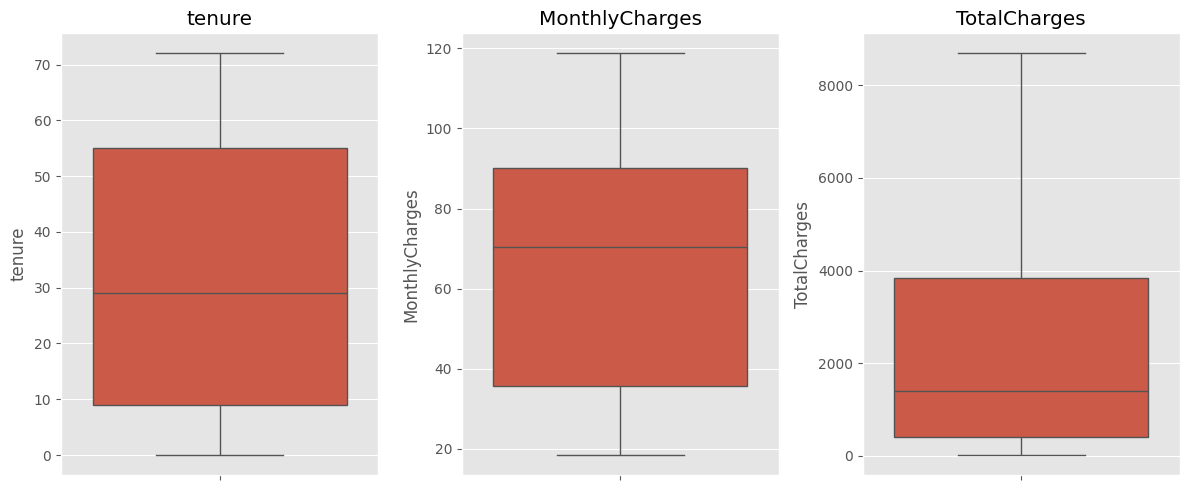

Total training records: 5634
Customers with at least one potential outlier: 0


In [44]:
numerical_columns = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]
outlier_results = []

for column in numerical_columns:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[column] < lower_bound) |
        (X_train[column] > upper_bound)
    ]

    outlier_results.append({
        'Feature': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)

print(outlier_df)
plt.figure(figsize=(12, 5))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(1, 3, i)

    sns.boxplot(y=X_train[column])

    plt.title(column)

plt.tight_layout()
plt.show()

outlier_mask = pd.Series(False, index=X_train.index)

for column in numerical_columns:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    column_mask = (
        (X_train[column] < lower_bound) |
        (X_train[column] > upper_bound)
    )

    outlier_mask = outlier_mask | column_mask

print("Total training records:", len(X_train))
print("Customers with at least one potential outlier:", outlier_mask.sum())
